# Thesis figures, one per cell

Each figure below is drawn by its own cell, reading its own data straight out of the committed
result files under `results/accord/`. No cell depends on any variable another figure's cell
created; each one loads what it needs, prints the values it is about to plot, draws, displays the
figure inline, and saves it as a PDF.

Run cells 1 to 3 first (setup, palette, small shared helpers). After that, every figure cell below
runs on its own, in any order.

**No credentialed data is shipped here.** MIMIC-III is a PhysioNet-credentialed dataset; every
result file this notebook reads is an aggregate (counts, rates, confusion-matrix cells, bootstrap
intervals) with no clinical text and no patient or admission identifiers.

## 1. Setup

In [1]:
%matplotlib inline
import os, sys, shutil, json, pathlib, math, statistics
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import norm
from scipy.optimize import brentq
import pandas as pd

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_BUNDLE = "/content/drive/MyDrive/This is paper/02_figures/colab_bundle"
    REPO = "/content/repo"
    os.makedirs(REPO, exist_ok=True)
    dst_results = os.path.join(REPO, "results")
    if os.path.exists(dst_results):
        shutil.rmtree(dst_results)
    shutil.copytree(os.path.join(DRIVE_BUNDLE, "results"), dst_results)
    print(f"copied bundle results: {DRIVE_BUNDLE}/results -> {dst_results}")
else:
    # Local run: this machine already has the repository checked out, so there is
    # nothing to mount or copy. REPO points straight at it.
    REPO = "/Users/rickygole/provenance-encoder"
    print(f"not running in Colab; reading directly from the local repository at {REPO}")

RESULTS = os.path.join(REPO, "results")
RESULTS_ACCORD = os.path.join(RESULTS, "accord")
FIGDIR = os.path.join(REPO, "accord", "thesis", "figures")
os.makedirs(FIGDIR, exist_ok=True)

# Defensive only: no cell in this notebook resamples or fits anything. Every
# bootstrap interval plotted below was already computed upstream (the seed is
# recorded inside the source JSON, typically 42) and is simply read and plotted.
np.random.seed(42)

n_json = sum(1 for _ in pathlib.Path(RESULTS_ACCORD).rglob("*.json"))
print("REPO           =", REPO)
print("RESULTS_ACCORD =", RESULTS_ACCORD)
print("FIGDIR         =", FIGDIR)
print("json files under results/accord:", n_json)

not running in Colab; reading directly from the local repository at /Users/rickygole/provenance-encoder
REPO           = /Users/rickygole/provenance-encoder
RESULTS_ACCORD = /Users/rickygole/provenance-encoder/results/accord
FIGDIR         = /Users/rickygole/provenance-encoder/accord/thesis/figures
json files under results/accord: 94


## 2. Shared palette

Four colours plus a red accent, used by name in every figure cell below (`DARK`, `MID`, `FILL`,
`DEAD`, `RED`). They differ in **lightness**, not just hue, so the figures still separate correctly
in a black-and-white print; the readout below prints that separation. This is the same palette
already established for this bundle in `Thesis_Figures_Restyle.ipynb`.

In [2]:
DARK = "#0A2795"   # bars, lines, primary emphasis (royal blue)
MID  = "#00817B"   # secondary series, reference lines, muted text (deep teal)
FILL = "#FFD166"   # bar fills, shaded bands (vivid amber)
DEAD = "#8E99A6"   # de-emphasised or retracted elements (cool grey)
RED  = "#D81E05"   # used sparingly: marks a failure, a retraction, or an external comparator

def luminance(hexcolor):
    """Greyscale lightness a black-and-white printer or photocopier will produce."""
    r, g, b = [int(hexcolor[i:i + 2], 16) for i in (1, 3, 5)]
    return 0.299 * r + 0.587 * g + 0.114 * b

def _lin(c):
    c = c / 255.0
    return c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4

def contrast(hex_a, hex_b):
    """WCAG contrast ratio. Small text needs at least 4.5:1 against its background."""
    ls = []
    for h in (hex_a, hex_b):
        r, g, b = [_lin(int(h[i:i + 2], 16)) for i in (1, 3, 5)]
        ls.append(0.2126 * r + 0.7152 * g + 0.0722 * b)
    hi, lo = max(ls), min(ls)
    return (hi + 0.05) / (lo + 0.05)

print("greyscale lightness readout (0 = black, 255 = white); should be well separated:")
for name, hexcolor in (("DARK", DARK), ("MID", MID), ("FILL", FILL), ("DEAD", DEAD), ("RED", RED)):
    print(f"  {name:5s} {hexcolor}  {luminance(hexcolor):5.1f} / 255"
          f"   contrast on white {contrast(hexcolor, '#FFFFFF'):5.2f}:1")
main = sorted(luminance(h) for h in (DARK, MID, FILL))
gap = min(b - a for a, b in zip(main, main[1:]))
print(f"  smallest gap between the three main tones: {gap:.0f} "
      f"({'ok' if gap >= 40 else 'TOO CLOSE'}; under about 40 they merge in print)")
print(f"  black text on a FILL badge: {contrast('#000000', FILL):5.2f}:1")
print(f"  DARK text on a FILL badge : {contrast(DARK, FILL):5.2f}:1")
print("  colour-blind check: the distinction is blue vs teal vs amber plus a large")
print("  lightness step, never red against green; under Vienot protanope and")
print("  deuteranope simulation the closest of the three pairs is still dE 69 in CIELAB.")

greyscale lightness readout (0 = black, 255 = white); should be well separated:
  DARK  #0A2795   42.9 / 255   contrast on white 12.09:1
  MID   #00817B   89.7 / 255   contrast on white  4.74:1
  FILL  #FFD166  210.6 / 255   contrast on white  1.44:1
  DEAD  #8E99A6  151.2 / 255   contrast on white  2.89:1
  RED   #D81E05   82.8 / 255   contrast on white  5.11:1
  smallest gap between the three main tones: 47 (ok; under about 40 they merge in print)
  black text on a FILL badge: 14.56:1
  DARK text on a FILL badge :  8.38:1
  colour-blind check: the distinction is blue vs teal vs amber plus a large
  lightness step, never red against green; under Vienot protanope and
  deuteranope simulation the closest of the three pairs is still dE 69 in CIELAB.


## 3. Shared helpers

Small and genuinely reused across every figure cell below: the print-legible style (serif, small
fonts, embedded PDF fonts, no top/right spines), a dashed "chance" line style used by more than one
figure, and a `save_fig` function that writes the PDF and reports its path. Anything used by only
one figure is defined inside that figure's own cell instead, not here.

In [3]:
# Identical to the rcParams block in make_figures.py and to style.setup(), so the
# same figure drawn from any of the three is the same figure. Nothing here or in
# any figure cell below goes under 8 point.
plt.rcParams.update({
    "font.family": "serif",
    # Pinned so that this notebook, make_figures.py and style.py all draw the
    # same text metrics: DejaVu Serif ships with matplotlib and is present both
    # here and in Colab, where Times New Roman is not.
    "font.serif": ["DejaVu Serif"],
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "pdf.fonttype": 42,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "grid.linewidth": 0.3,
    "grid.color": "#DCE0E4",
    "lines.linewidth": 1.2,
    "figure.dpi": 150,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})

# Dashed reference-line style for a "chance" / null value; used by fig-intro-headline,
# fig-rule-precision and fig-disc-strata.
CHANCE_STYLE = dict(color=MID, linestyle="--", linewidth=1.0, zorder=1)

def save_fig(fig, filename):
    """Save a figure as a PDF into the thesis figures directory and report the path."""
    path = os.path.join(FIGDIR, filename)
    fig.savefig(path)
    print(f"saved: {path}")
    return path

# Long provenance notes and duplicate titles belong in the LaTeX caption,
# not inside the plot. Flip either to True to draw them again.
SHOW_INFIGURE_NOTES  = False
SHOW_INFIGURE_TITLES = False
print("in-figure notes and titles: off")


in-figure notes and titles: off


## 4. The data these figures are built from

Every figure below reads its numbers out of a stored result file. Nothing is
typed in from a draft, a note or from memory. This cell lists each file, checks
it is present, and shows its top-level keys, so the source material is visible
before a single figure is drawn.

If a file is missing here, the figure that depends on it will fail loudly rather
than fall back to a literal.

In [4]:
SOURCES = [
    ("results/accord/exemplar/exemplar_correctness_recomputed.json", "Fig 1, 13"),
    ("results/accord/diag/step0_1_join_and_calibration.json",        "Fig 1, 2, 3"),
    ("results/accord/diag/step2_signal_check.json",                  "Fig 1"),
    ("results/accord/decontam/corrected_gold_metrics.json",          "Fig 1, 7, 8"),
    ("results/accord/reconciliation_c28.json",                       "Fig 2"),
    ("results/accord/defect_free_strata.json",                       "Fig 3"),
    ("results/accord/prevalence_replication/sweep_results.json",     "Fig 4"),
    ("results/accord/decontam/accord_v2_decontam_gold_aggregate.json","Fig 5"),
    ("results/accord/generality/transfer_results_correct.json",      "Fig 5"),
    ("results/accord/section6_auroc_power.json",                     "Fig 6"),
    ("results/task_runs.json",                                       "Fig 6"),
    ("results/accord/stats/intervals.json",                          "Fig 7"),
    ("results/accord/control/final_report.json",                     "Fig 7, 8"),
    ("results/accord/scaling/scaling_results.json",                  "Fig 9"),
    ("results/accord/selection/threshold_robustness_results.json",   "Fig 10"),
    ("results/accord/diag/step3_baselines.json",                     "Fig 12"),
    ("results/accord/differential/exp1a_gold_error_rates_by_group.json", "Fig 10"),
    ("results/accord/number_provenance_audit.json",                  "provenance record"),
]

print(f"{'file':66s} {'kB':>6}  used by")
print("-" * 100)
missing = []
for rel, used in SOURCES:
    path = os.path.join(REPO, rel)
    if not os.path.exists(path):
        print(f"{rel:66s} {'--':>6}  MISSING")
        missing.append(rel)
        continue
    kb = os.path.getsize(path) / 1024
    print(f"{rel:66s} {kb:6.1f}  {used}")

print()
if missing:
    print(f"{len(missing)} of {len(SOURCES)} files are missing. The figures that read them will")
    print("fail rather than substitute a value. Check that the Drive bundle copied correctly.")
else:
    print(f"all {len(SOURCES)} source files present")

print()
print("top-level keys of each file")
print("-" * 100)
for rel, _ in SOURCES:
    path = os.path.join(REPO, rel)
    if not os.path.exists(path):
        continue
    try:
        d = json.load(open(path))
    except Exception as e:
        print(f"{rel}: could not parse ({e})")
        continue
    keys = list(d.keys()) if isinstance(d, dict) else [f"(list of {len(d)})"]
    shown = ", ".join(str(k) for k in keys[:6])
    more = f"  ... and {len(keys) - 6} more" if len(keys) > 6 else ""
    print(f"{rel.split('/')[-1]:52s} {shown}{more}")


file                                                                   kB  used by
----------------------------------------------------------------------------------------------------
results/accord/exemplar/exemplar_correctness_recomputed.json          1.4  Fig 1, 13
results/accord/diag/step0_1_join_and_calibration.json                 4.2  Fig 1, 2, 3
results/accord/diag/step2_signal_check.json                           2.0  Fig 1
results/accord/decontam/corrected_gold_metrics.json                   1.1  Fig 1, 7, 8
results/accord/reconciliation_c28.json                               12.8  Fig 2
results/accord/defect_free_strata.json                                1.6  Fig 3
results/accord/prevalence_replication/sweep_results.json             16.8  Fig 4
results/accord/decontam/accord_v2_decontam_gold_aggregate.json       13.5  Fig 5
results/accord/generality/transfer_results_correct.json               0.9  Fig 5
results/accord/section6_auroc_power.json                              0

## Figure 1: `fig-pipeline-status`

**Step 1. The data.** Read from `results/accord/exemplar/exemplar_correctness_recomputed.json`, `results/accord/diag/step0_1_join_and_calibration.json`, `results/accord/diag/step2_signal_check.json`, `results/accord/decontam/corrected_gold_metrics.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [5]:
p_exemplar = os.path.join(RESULTS_ACCORD, "exemplar", "exemplar_correctness_recomputed.json")
d_exemplar = json.load(open(p_exemplar))
ex = d_exemplar["rule_1_2_pooled"]
defect_rate = ex["n_wrong"] / ex["n_resolved"]

p_step01 = os.path.join(RESULTS_ACCORD, "diag", "step0_1_join_and_calibration.json")
d_step01 = json.load(open(p_step01))
xtab = d_step01["weak_confidence_is_degenerate"]["crosstab_label_x_confidence"]
weak_pos = xtab["0.95"]["contradiction"]
weak_neg = xtab["1.0"]["not_contradiction"]
weak_pos_rate = weak_pos / (weak_pos + weak_neg)

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
pharm_rate_all = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]["base_rate"]
ratio = weak_pos_rate / pharm_rate_all

p_decontam = os.path.join(RESULTS_ACCORD, "decontam", "corrected_gold_metrics.json")
d_decontam = json.load(open(p_decontam))
auroc = d_decontam["aggregate"]["ensemble_auroc"]
ci = d_decontam["aggregate"]["ensemble_ci95"]

print("fig-pipeline-status: values plotted")
print(f"  exemplar defect rate, rule_1_2_pooled     : {ex['n_wrong']}/{ex['n_resolved']} = {defect_rate:.4f}")
print(f"  weak-label positive rate, train pool       : {weak_pos}/{weak_pos + weak_neg} = {weak_pos_rate:.4f}")
print(f"  pharmacist base rate, n=299 (ambig=neg)     : {pharm_rate_all:.4f}")
print(f"  prevalence mismatch ratio                   : {ratio:.1f}x")
print(f"  decontaminated 3-seed ensemble AUROC         : {auroc:.4f}, 95% CI [{ci[0]:.3f}, {ci[1]:.3f}]")
print("  two categorical, unsourced-by-number badges (stage 'Detector training'): see markdown above")

# Six evenly spaced columns. Every string below is wrapped to at most about
# twelve characters so that no badge and no diagnostic can grow wider than
# its column: the previous version wrapped to the natural phrase length and
# the long badges collided with their neighbours and with the row beneath.

fig-pipeline-status: values plotted
  exemplar defect rate, rule_1_2_pooled     : 65/137 = 0.4745
  weak-label positive rate, train pool       : 1425/1679 = 0.8487
  pharmacist base rate, n=299 (ambig=neg)     : 0.0401
  prevalence mismatch ratio                   : 21.2x
  decontaminated 3-seed ensemble AUROC         : 0.5145, 95% CI [0.321, 0.703]
  two categorical, unsourced-by-number badges (stage 'Detector training'): see markdown above


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-pipeline-status.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-pipeline-status.pdf


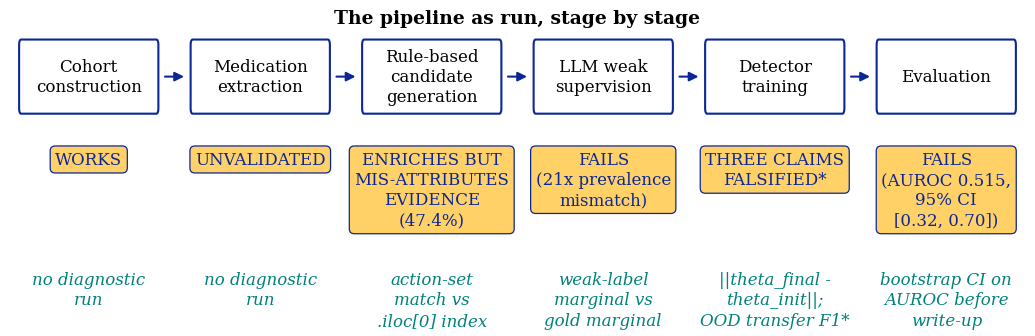

In [6]:
fig, ax = plt.subplots(figsize=(7.0, 2.25))
fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01)
ax.set_xlim(0, 6)
ax.set_ylim(0.255, 1)
ax.axis("off")

stages = ["Cohort\nconstruction", "Medication\nextraction",
          "Rule-based\ncandidate\ngeneration", "LLM weak\nsupervision",
          "Detector\ntraining", "Evaluation"]
badges = ["WORKS", "UNVALIDATED",
          f"ENRICHES BUT\nMIS-ATTRIBUTES\nEVIDENCE\n({defect_rate * 100:.1f}%)",
          f"FAILS\n({ratio:.0f}x prevalence\nmismatch)",
          "THREE CLAIMS\nFALSIFIED*",
          f"FAILS\n(AUROC {auroc:.3f},\n95% CI\n[{ci[0]:.2f}, {ci[1]:.2f}])"]
# Written out rather than left as a dash: the thesis bans en and em dashes,
# and a double hyphen renders on canvas as something a reader reads as one.
diagnostics = ["no diagnostic\nrun", "no diagnostic\nrun",
               "action-set\nmatch vs\n.iloc[0] index",
               "weak-label\nmarginal vs\ngold marginal",
               "||theta_final -\ntheta_init||;\nOOD transfer F1*",
               "bootstrap CI on\nAUROC before\nwrite-up"]

n = len(stages)
box_w = 0.80
y_box, box_h = 0.755, 0.155
y_badge_top, y_diag_top = 0.665, 0.395
xs = np.linspace(0.5, 5.5, n)
for i, (x, s, b, dtxt) in enumerate(zip(xs, stages, badges, diagnostics)):
    box = FancyBboxPatch((x - box_w / 2, y_box), box_w, box_h,
                          boxstyle="round,pad=0.006,rounding_size=0.012",
                          linewidth=1.0, edgecolor=DARK, facecolor="white")
    ax.add_patch(box)
    ax.text(x, y_box + box_h / 2, s, ha="center", va="center", fontsize=8.0,
            linespacing=1.25)
    if i < n - 1:
        ax.annotate("", xy=(xs[i + 1] - box_w / 2 - 0.02, y_box + box_h / 2),
                     xytext=(x + box_w / 2 + 0.02, y_box + box_h / 2),
                     arrowprops=dict(arrowstyle="-|>", color=DARK, lw=1.0))
    ax.text(x, y_badge_top, b, ha="center", va="top", fontsize=8.0, color=DARK,
            linespacing=1.25,
            bbox=dict(boxstyle="round,pad=0.3", facecolor=FILL, edgecolor=DARK, linewidth=0.6))
    ax.text(x, y_diag_top, dtxt, ha="center", va="top", fontsize=8.0, style="italic",
            color=MID, linespacing=1.3)

ax.text(3.0, 0.985, "The pipeline as run, stage by stage", ha="center", va="top",
        fontsize=9.0, weight="bold")
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.02,
          "*Categorical only (not re-plotted with a number): CORRECTIONS.md C1/C2/C4 document that the\n"
          "authority-weight and rule-F1 claims did not survive re-audit; no committed result file in this\n"
          "repo carries the underlying numbers, so they are not re-typed here.",
          ha="center", fontsize=8.0, color=MID)

save_fig(fig, "fig-pipeline-status.pdf")
plt.show()

## Figure 2: `fig-intro-headline`

**Step 1. The data.** Read from `results/accord/diag/step0_1_join_and_calibration.json`, `results/accord/differential/exp1a_gold_error_rates_by_group.json`, `results/accord/diag/step2_signal_check.json`, `results/accord/stats/intervals.json`, `results/accord/reconciliation_c28.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [7]:
p_step01 = os.path.join(RESULTS_ACCORD, "diag", "step0_1_join_and_calibration.json")
d_step01 = json.load(open(p_step01))
xtab = d_step01["weak_confidence_is_degenerate"]["crosstab_label_x_confidence"]
weak_pos, weak_neg = xtab["0.95"]["contradiction"], xtab["1.0"]["not_contradiction"]
weak_n = weak_pos + weak_neg
weak_rate = weak_pos / weak_n

p_exp1a = os.path.join(RESULTS_ACCORD, "differential", "exp1a_gold_error_rates_by_group.json")
d_exp1a = json.load(open(p_exp1a))
lang = d_exp1a["language_group3"]
pred_pos = sum(g["TP"] + g["FP"] for g in lang)
pred_n = sum(g["n"] for g in lang)
pred_rate = pred_pos / pred_n

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
d299 = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]
pharm_pos, pharm_n = d299["n_pos"], d299["n"]
pharm_rate = pharm_pos / pharm_n

p_intervals = os.path.join(RESULTS_ACCORD, "stats", "intervals.json")
d_intervals = json.load(open(p_intervals))
mcc = d_intervals["E2_mcc_intervals"]
order = ["gpt4o_zeroshot", "gpt4o_fewshot", "accord_binary_at_0.5_253core", "llama_baseline"]
labels = ["GPT-4o\nz.s.", "GPT-4o\nf.s.", "ACCORD", "Llama 3\n8B"]

p_c28 = os.path.join(RESULTS_ACCORD, "reconciliation_c28.json")
d_c28 = json.load(open(p_c28))
accord_pred = d_c28["a_what_each_number_counts"]["278"]
weak_marginal = d_c28["a_what_each_number_counts"]["261"]

def wilson_ci(k, n, z=1.959963984540054):
    """Wilson score interval for a binomial proportion; closed-form, deterministic."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = p + z ** 2 / (2 * n)
    adj = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2))
    lo = (centre - adj) / denom
    hi = (centre + adj) / denom
    return (max(0.0, lo), min(1.0, hi))

print("fig-intro-headline: values plotted")
print(f"  weak-label positive rate, train pool     : {weak_pos}/{weak_n} = {weak_rate:.4f}")
print(f"  left-panel middle bar (exp1a TP+FP sum)  : {pred_pos}/{pred_n} = {pred_rate:.4f}  (the weak labeller on the gold set, NOT ACCORD)")
print(f"  pharmacist true rate, gold set (n=299)   : {pharm_pos}/{pharm_n} = {pharm_rate:.4f}")
for k in order:
    v = mcc[k]
    print(f"  MCC {k:32s}: {v['mcc']:+.4f}  95% CI [{v['ci95'][0]:+.4f}, {v['ci95'][1]:+.4f}]")
print(f"  reconciliation_c28: ACCORD predicted-positive = {accord_pred['value']}/{accord_pred['denominator']}"
      f"  (accord_pred == 'contradiction')")
print(f"  reconciliation_c28: weak-labeller marginal    = {weak_marginal['value']}/{weak_marginal['denominator']}"
      f"  (weak_label == 'contradiction', matches the {pred_pos}/{pred_n} bar above)")

# The right panel gets the wider share: its four category labels need room
# side by side, while the left panel's y labels live outside its axes.

fig-intro-headline: values plotted
  weak-label positive rate, train pool     : 1425/1679 = 0.8487
  left-panel middle bar (exp1a TP+FP sum)  : 261/299 = 0.8729  (the weak labeller on the gold set, NOT ACCORD)
  pharmacist true rate, gold set (n=299)   : 12/299 = 0.0401
  MCC gpt4o_zeroshot                  : +0.1089  95% CI [-0.0319, +0.2484]
  MCC gpt4o_fewshot                   : +0.0117  95% CI [-0.1120, +0.1319]
  MCC accord_binary_at_0.5_253core    : -0.0070  95% CI [-0.1626, +0.0753]
  MCC llama_baseline                  : -0.0436  95% CI [-0.2337, +0.0563]
  reconciliation_c28: ACCORD predicted-positive = 278/299  (accord_pred == 'contradiction')
  reconciliation_c28: weak-labeller marginal    = 261/299  (weak_label == 'contradiction', matches the 261/299 bar above)


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-intro-headline.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-intro-headline.pdf


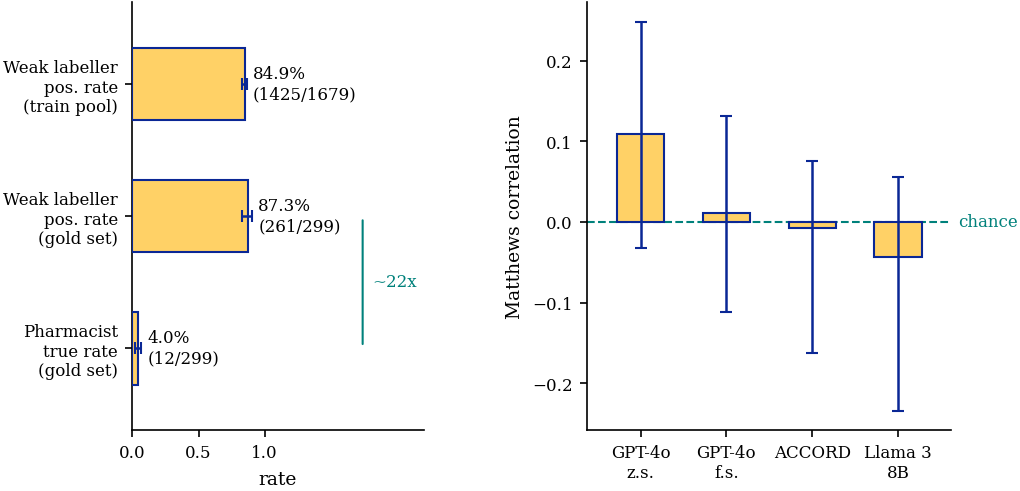

In [8]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(7.0, 3.5),
                               gridspec_kw={"width_ratios": [1.0, 1.25]})
fig.subplots_adjust(left=0.155, right=0.935, top=0.97, bottom=0.155, wspace=0.50)

# Middle bar: 261/299 is the weak labeller's marginal on the gold set, not
# ACCORD's own predicted-positive count (that is 278/299). reconciliation_c28.json
# exists to settle exactly this, and the bar was previously mislabelled ACCORD.
bars = [("Weak labeller\npos. rate\n(train pool)", weak_pos, weak_n, wilson_ci(weak_pos, weak_n)),
        ("Weak labeller\npos. rate\n(gold set)", pred_pos, pred_n, wilson_ci(pred_pos, pred_n)),
        ("Pharmacist\ntrue rate\n(gold set)", pharm_pos, pharm_n, wilson_ci(pharm_pos, pharm_n))]
ypos = np.arange(len(bars))[::-1]
rates = [b[1] / b[2] for b in bars]
los = [b[3][0] for b in bars]
his = [b[3][1] for b in bars]
errs = [[r - lo for r, lo in zip(rates, los)], [hi - r for r, hi in zip(rates, his)]]
axL.barh(ypos, rates, color=FILL, edgecolor=DARK, height=0.55,
          xerr=errs, ecolor=DARK, capsize=3, zorder=3)
# Value labels clear the upper CI cap rather than starting at the bar end,
# and wrap to two lines so they cannot reach the ratio bracket on the right.
for y, b, r, hi in zip(ypos, bars, rates, his):
    axL.text(hi + 0.045, y, f"{r * 100:.1f}%\n({b[1]}/{b[2]})", va="center",
             ha="left", fontsize=8.0, linespacing=1.25)
axL.set_yticks(ypos)
axL.set_yticklabels([b[0] for b in bars], fontsize=8.0)
axL.set_xlim(0, 2.2)
axL.set_ylim(-0.62, 2.62)
axL.set_xticks([0, 0.5, 1.0])
axL.set_xlabel("rate")
axL.spines[["top", "right"]].set_visible(False)
if SHOW_INFIGURE_TITLES: axL.set_title(f"Marginal, weak label vs.\\ truth ({weak_rate / pharm_rate:.0f}x)", fontsize=8.5)
# The bracket compares the two bars measured on the same 299-pair gold set.
# It used to span the training-pool bar and the gold-set bar, which have
# different denominators.
gold_ratio = (pred_pos / pred_n) / (pharm_pos / pharm_n)
x_bracket = 1.74
axL.annotate("", xy=(x_bracket, ypos[2]), xytext=(x_bracket, ypos[1]),
              arrowprops=dict(arrowstyle="-", color=MID, lw=1.0))
axL.text(x_bracket + 0.07, (ypos[1] + ypos[2]) / 2, f"~{gold_ratio:.0f}x",
          va="center", ha="left", fontsize=8.0, color=MID)

xs = np.arange(4)
vals = [mcc[k]["mcc"] for k in order]
ci_lo = [mcc[k]["ci95"][0] for k in order]
ci_hi = [mcc[k]["ci95"][1] for k in order]
err = [[v - lo for v, lo in zip(vals, ci_lo)], [hi - v for v, hi in zip(vals, ci_hi)]]
axR.axhline(0, **CHANCE_STYLE)
axR.bar(xs, vals, yerr=err, color=FILL, edgecolor=DARK, capsize=3,
         width=0.55, linewidth=1.0, ecolor=DARK, zorder=3)
axR.set_xticks(xs)
axR.set_xticklabels(labels, fontsize=8.0)
axR.set_xlim(-0.62, 3.62)
axR.set_ylabel("Matthews correlation")
if SHOW_INFIGURE_TITLES: axR.set_title("MCC, 95% CI, n=253", fontsize=8.5)
# Sits at the end of the reference line it names, outside the plotted range,
# so it cannot land on a bar or an interval.
axR.text(3.70, 0.0, "chance", fontsize=8.0, color=MID, va="center", ha="left",
         clip_on=False)
axR.spines[["top", "right"]].set_visible(False)

if SHOW_INFIGURE_TITLES: fig.suptitle("The number that determines the rest of the thesis", fontsize=9.0, y=0.97)
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.02,
          f"Left-panel middle bar (weak labeller gold-set marginal): {pred_pos}/{pred_n}, summed from per-group counts in\n"
          f"exp1a_gold_error_rates_by_group.json. reconciliation_c28.json confirms this equals the weak-labeller marginal (not\n"
          f"ACCORD's own {accord_pred['value']}/{accord_pred['denominator']} predicted-positive count); see the markdown note above this cell.",
          ha="center", fontsize=8.0, color=MID)

save_fig(fig, "fig-intro-headline.pdf")
plt.show()

## Figure 3: `fig-rule-precision`

**Step 1. The data.** Read from `results/accord/defect_free_strata.json`, `results/accord/stats/intervals.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [9]:
p_strata = os.path.join(RESULTS_ACCORD, "defect_free_strata.json")
d_strata = json.load(open(p_strata))

p_intervals = os.path.join(RESULTS_ACCORD, "stats", "intervals.json")
d_intervals = json.load(open(p_intervals))
e3 = d_intervals["E3_defect_free_stratum"]

per_rule = [s for s in d_strata["strata"] if s["name"].startswith("rule ")]
per_rule = sorted(per_rule, key=lambda s: s["name"])

print("fig-rule-precision: values plotted")
for s in per_rule:
    print(f"  {s['name']:8s}  n={s['n']:4d}  pos={s['pos']:3d}  AUROC={s['auroc']:.4f}")
print(f"  pooled rules 3+4 (defect-free) 95% CI: [{e3['unstratified_ci95'][0]:.4f}, {e3['unstratified_ci95'][1]:.4f}]"
      f"  (n={e3['n']}, pos={e3['n_pos']})")

fig-rule-precision: values plotted
  rule 1    n= 134  pos=  3  AUROC=0.6514
  rule 2    n=  31  pos=  3  AUROC=0.2262
  rule 3    n=  79  pos=  4  AUROC=0.5100
  rule 4    n=  55  pos=  2  AUROC=0.2358
  pooled rules 3+4 (defect-free) 95% CI: [0.2217, 0.7615]  (n=134, pos=6)


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-rule-precision.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-rule-precision.pdf


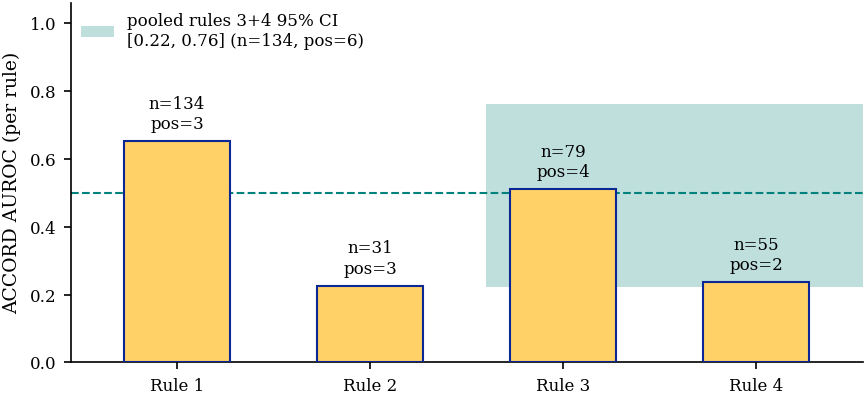

In [10]:
fig, ax = plt.subplots(figsize=(6.0, 3.2))
fig.subplots_adjust(left=0.105, right=0.985, top=0.97, bottom=0.11)
xs = np.arange(len(per_rule))
aurocs = [s["auroc"] for s in per_rule]
x_lo, x_hi = -0.55, 3.55
ax.set_xlim(x_lo, x_hi)
# Reference band: pooled rules 3+4 (defect-free) bootstrap CI, drawn across the
# rule-3 and rule-4 bars it actually describes. It is drawn in data coordinates
# and behind the bars: the earlier axhspan took axes fractions, which put its
# left edge on Rule 2, and it painted over the Rule 3 bar.
ax.fill_between([2 - 0.4, x_hi], e3["unstratified_ci95"][0], e3["unstratified_ci95"][1],
                color=MID, alpha=0.25, linewidth=0, zorder=0,
                label=f"pooled rules 3+4 95% CI\n[{e3['unstratified_ci95'][0]:.2f}, {e3['unstratified_ci95'][1]:.2f}] (n={e3['n']}, pos={e3['n_pos']})")
ax.axhline(0.5, **CHANCE_STYLE)
ax.bar(xs, aurocs, color=FILL, edgecolor=DARK, width=0.55, zorder=3)
for x, s in zip(xs, per_rule):
    ax.text(x, s["auroc"] + 0.025, f"n={s['n']}\npos={s['pos']}", ha="center",
            va="bottom", fontsize=8.0, linespacing=1.25, zorder=4)
ax.set_xticks(xs)
ax.set_xticklabels([s["name"].replace("rule ", "Rule ") for s in per_rule])
ax.set_ylabel("ACCORD AUROC (per rule)")
ax.set_ylim(0, 1.06)
ax.legend(loc="upper left", fontsize=8.0, frameon=False, borderaxespad=0.2)
ax.spines[["top", "right"]].set_visible(False)
if SHOW_INFIGURE_TITLES: ax.set_title("ACCORD's own ranking performance does not exceed chance\nwithin any single rule", fontsize=8.3)
if SHOW_INFIGURE_NOTES: fig.text(0.02, 0.02,
          "Deviation from spec: per-rule ACCORD precision (as in the written spec) is not in any\n"
          "committed result file; per-rule AUROC is (defect_free_strata.json) and is shown instead.\n"
          "Individual-rule CIs are not computable here (per-pair scores not committed); only the\n"
          "pooled rules-3+4 CI (stats/intervals.json E3) is available and is shown as a reference band.",
          fontsize=8.0, color=MID)
fig.tight_layout(rect=[0, 0.10, 1, 1])

save_fig(fig, "fig-rule-precision.pdf")
plt.show()

## Figure 4: `fig-prevalence-response`

**Step 1. The data.** Read from `results/accord/prevalence_replication/sweep_results.json`, `results/accord/diag/step0_1_join_and_calibration.json`, `results/accord/diag/step2_signal_check.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [11]:
p_sweep = os.path.join(RESULTS_ACCORD, "prevalence_replication", "sweep_results.json")
d_sweep = json.load(open(p_sweep))
models = d_sweep["models"]
prompts = ["A_bare", "B_baserate_abstain"]
# The second row label is wrapped: on one line it ran the full height of its
# panel and collided with the row above it.
prompt_label = {"A_bare": "bare prompt", "B_baserate_abstain": "base rate stated,\nabstention allowed"}

# The "clinical" comparison point: same weak-label-vs-pharmacist shift as figures 1 and 2,
# recomputed here from the same two diagnostic files (not typed in).
p_step01 = os.path.join(RESULTS_ACCORD, "diag", "step0_1_join_and_calibration.json")
d_step01 = json.load(open(p_step01))
xtab = d_step01["weak_confidence_is_degenerate"]["crosstab_label_x_confidence"]
weak_pos, weak_neg = xtab["0.95"]["contradiction"], xtab["1.0"]["not_contradiction"]
clinical_y = weak_pos / (weak_pos + weak_neg)

p_step2 = os.path.join(RESULTS_ACCORD, "diag", "step2_signal_check.json")
d_step2 = json.load(open(p_step2))
clinical_x = d_step2["contra_prob_vs_pharm_label__ambiguous_as_negative_n299"]["base_rate"]

print("fig-prevalence-response: values plotted")
print(f"  models: {models}")
print(f"  clinical marker (true prevalence, labeller positive rate): ({clinical_x:.4f}, {clinical_y:.4f})")
for pr in prompts:
    for m in models:
        pts = {p: d_sweep["results"][m][pr].get(p) for p in ["0.02", "0.05", "0.1", "0.25"]}
        rates = {p: (e["positive_rate_of_decided"] if e else None) for p, e in pts.items()}
        print(f"  {m:14s} / {prompt_label[pr]:38s}: {rates}")

fig-prevalence-response: values plotted
  models: ['llama3:8b', 'granite3.3:8b', 'qwen3:8b']
  clinical marker (true prevalence, labeller positive rate): (0.0401, 0.8487)
  llama3:8b      / bare prompt                           : {'0.02': 0.07, '0.05': 0.17, '0.1': 0.06, '0.25': 0.12}
  granite3.3:8b  / bare prompt                           : {'0.02': 0.05, '0.05': 0.07, '0.1': 0.1, '0.25': 0.16}
  qwen3:8b       / bare prompt                           : {'0.02': 0.02, '0.05': 0.03, '0.1': 0.05, '0.25': 0.09}
  llama3:8b      / base rate stated,
abstention allowed  : {'0.02': 0.0410958904109589, '0.05': 0.10975609756097561, '0.1': 0.05405405405405406, '0.25': 0.07352941176470588}
  granite3.3:8b  / base rate stated,
abstention allowed  : {'0.02': 0.030612244897959183, '0.05': 0.04, '0.1': 0.09, '0.25': 0.17}
  qwen3:8b       / base rate stated,
abstention allowed  : {'0.02': 0.0, '0.05': 0.0, '0.1': 0.025, '0.25': 0.02666666666666667}


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-prevalence-response.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-prevalence-response.pdf


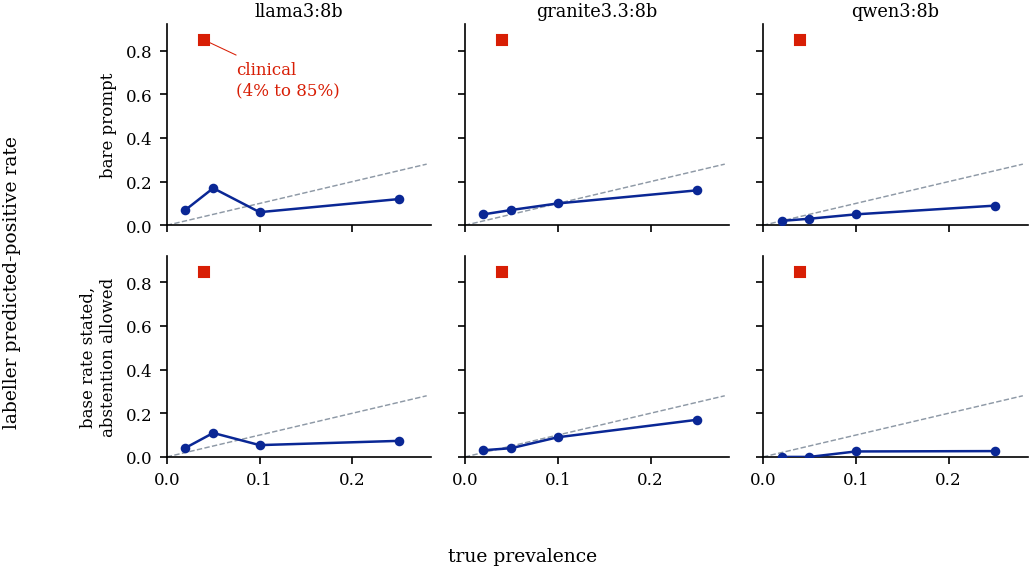

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(7.0, 4.0), sharex=True, sharey=True)
for r, pr in enumerate(prompts):
    for c, m in enumerate(models):
        ax = axes[r, c]
        xs, ys = [], []
        for p in ["0.02", "0.05", "0.1", "0.25"]:
            e = d_sweep["results"][m][pr].get(p)
            if e:
                xs.append(float(p))
                ys.append(e["positive_rate_of_decided"])
        ax.plot([0, .28], [0, .28], ls="--", lw=.7, color=DEAD, zorder=1)
        ax.plot(xs, ys, "-o", color=DARK, ms=3.6, lw=1.2, zorder=3)
        ax.plot([clinical_x], [clinical_y], "s", color=RED, ms=5, zorder=4)
        if r == 0 and c == 0:
            ax.annotate(f"clinical\n({clinical_x * 100:.0f}% to {clinical_y * 100:.0f}%)",
                         (clinical_x, clinical_y), xytext=(0.075, 0.60),
                         fontsize=8.0, color=RED, linespacing=1.25,
                         arrowprops=dict(arrowstyle="-", lw=.5, color=RED))
        ax.set_xlim(0, .285)
        ax.set_ylim(0, .92)
        # Panel heading, not a figure title: it names which labeller this column is.
        if r == 0:
            ax.set_title(m, fontsize=8.5, pad=4)
        if c == 0:
            ax.set_ylabel(prompt_label[pr], fontsize=8.0, linespacing=1.3)
        ax.tick_params(labelsize=8)
fig.supxlabel("true prevalence", fontsize=9.0, y=0.028)
fig.supylabel("labeller predicted-positive rate", fontsize=9.0, x=0.005)
if SHOW_INFIGURE_TITLES: fig.suptitle("The labeller under-responds to prevalence, but nowhere near the clinical shift",
              fontsize=9.5, x=0.02, ha="left", y=0.99)
if SHOW_INFIGURE_NOTES: fig.text(0.02, 0.925, "dashed: perfect calibration", fontsize=8.0, color="0.4")
fig.tight_layout(rect=[0.022, 0.058, 1, 1])

save_fig(fig, "fig-prevalence-response.pdf")
plt.show()

## Figure 5: `fig-falsification`

**Step 1. The data.** Read from `results/accord/decontam/accord_v2_decontam_gold_aggregate.json`, `results/accord/generality/transfer_results_correct.json`, `results/accord/number_provenance_audit.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [13]:
p_agg = os.path.join(RESULTS_ACCORD, "decontam", "accord_v2_decontam_gold_aggregate.json")
d_agg = json.load(open(p_agg))
aN, aD = d_agg["aggregate"]["alpha_n"]["mean"], d_agg["aggregate"]["alpha_d"]["mean"]
sN, sD = d_agg["aggregate"]["alpha_n"]["std"], d_agg["aggregate"]["alpha_d"]["std"]

p_transfer = os.path.join(RESULTS_ACCORD, "generality", "transfer_results_correct.json")
d_transfer = json.load(open(p_transfer))
f1 = [d_transfer["hf_reference"]["rule_type_f1"], d_transfer["sepsis"]["rule_type_f1"], d_transfer["aki"]["rule_type_f1"]]
cohort_labels = ["HF\n(in domain)", "sepsis", "AKI"]

p_audit = os.path.join(RESULTS_ACCORD, "number_provenance_audit.json")
d_audit = json.load(open(p_audit))
claim = next(r for r in d_audit["records"] if "45.2" in r["claim"])
# The 45.2% held-out rule-accuracy reference line has been REMOVED from this
# figure: 0.4515 appears in no result file anywhere on disk, only in figure code
# and in the audit record printed below, which flags it as untraceable.

print("fig-falsification: values plotted")
print(f"  alpha_N (nursing authority scale), 3-seed mean +/- std : {aN:.4f} +/- {sN:.4f}")
print(f"  alpha_D (discharge authority scale), 3-seed mean +/- std: {aD:.4f} +/- {sD:.4f}")
for lab, v in zip(cohort_labels, f1):
    print(f"  rule-type F1, {lab.replace(chr(10), ' '):16s}: {v:.4f}")
print("  alpha initialisation 0.5 / 1.0: a stated design constant, not a measurement;")
print("    it is in no result file, and the figure legend now says so.")
print("  NOT plotted (removed): held-out rule-prediction accuracy 0.4515")
print(f"  number_provenance_audit.json claim record: {claim}")

fig-falsification: values plotted
  alpha_N (nursing authority scale), 3-seed mean +/- std : 0.5076 +/- 0.0006
  alpha_D (discharge authority scale), 3-seed mean +/- std: 1.0038 +/- 0.0010
  rule-type F1, HF (in domain)  : 0.9603
  rule-type F1, sepsis          : 0.0654
  rule-type F1, AKI             : 0.0595
  alpha initialisation 0.5 / 1.0: a stated design constant, not a measurement;
    it is in no result file, and the figure legend now says so.
  NOT plotted (removed): held-out rule-prediction accuracy 0.4515
  number_provenance_audit.json claim record: {'claim': '45.2% held-out rule-prediction accuracy (recomputes to 0.4515)', 'tex_location': 'ch6:291', 'artifact': 'gold-standard CSV per ch6 caption', 'artifact_exists': False, 'reported': 0.452, 'recomputed': None, 'verdict': 'UNTRACEABLE', 'blast_radius': 'body', 'note': "Caption asserts it 'recomputes to 0.4515 directly from the gold-standard CSV' but no results file records 0.4515."}


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-falsification.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-falsification.pdf


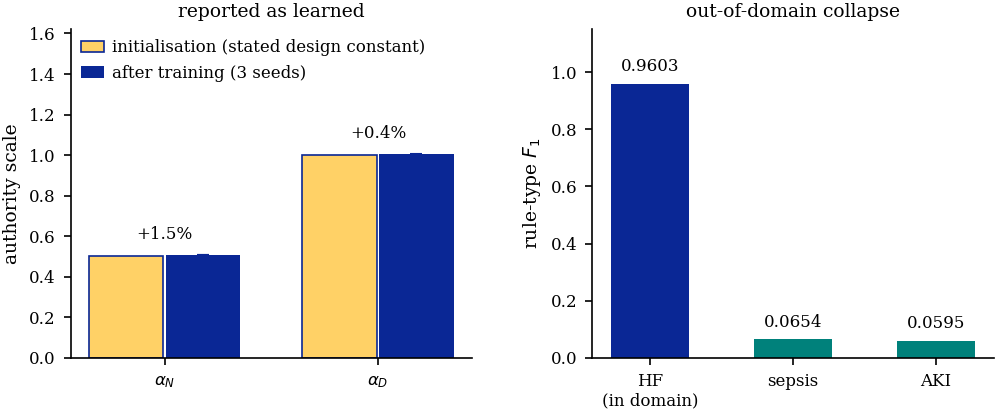

In [14]:
fig, (a, b) = plt.subplots(1, 2, figsize=(6.8, 2.9))
fig.subplots_adjust(left=0.085, right=0.99, top=0.90, bottom=0.145, wspace=0.30)
x = [0, 1]
# The two initialisation values are a stated design constant, not a measurement:
# no result file records them. The legend says so, because the percent changes
# beside the bars are computed against them.
a.bar([i - .18 for i in x], [0.5, 1.0], .35, color=FILL, edgecolor=DARK,
      linewidth=0.8, label="initialisation (stated design constant)")
a.bar([i + .18 for i in x], [aN, aD], .35, color=DARK, yerr=[sN, sD], capsize=3,
      ecolor=DARK, label="after training (3 seeds)")
for i, (init, fin) in enumerate([(0.5, aN), (1.0, aD)]):
    a.text(i, max(init, fin) + .06, f"{100 * (fin - init) / init:+.1f}%", ha="center",
           va="bottom", fontsize=8.0)
a.set_xticks(x)
a.set_xticklabels([r"$\alpha_N$", r"$\alpha_D$"])
a.set_ylim(0, 1.62)
a.set_ylabel("authority scale")
a.set_title("reported as learned", fontsize=9.0)
a.legend(fontsize=8.0, frameon=False, loc="upper left", borderaxespad=0.2,
         handlelength=1.4, handletextpad=0.5)

bars = b.bar(cohort_labels, f1, color=[DARK, MID, MID], width=.55)
for rct, v in zip(bars, f1):
    b.text(rct.get_x() + rct.get_width() / 2, v + .03, f"{v:.4f}", ha="center",
           va="bottom", fontsize=8.0)
b.set_ylim(0, 1.15)
b.set_ylabel(r"rule-type $F_1$")
b.set_title("out-of-domain collapse", fontsize=9.0)

save_fig(fig, "fig-falsification.pdf")
plt.show()

## Figure 6: `fig-power`

**Step 1. The data.** Read from `results/accord/section6_auroc_power.json`, `results/task_runs.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [15]:
p_power = os.path.join(RESULTS_ACCORD, "section6_auroc_power.json")
pw = json.load(open(p_power))
mda = pw["minimum_detectable_auc"]
n_pos_study = pw["n_positives"]
n_neg_study = pw["n_negatives"]
alpha_study = pw["alpha"]
power_study = pw["power"]

p_task_runs = os.path.join(RESULTS, "task_runs.json")
d_task_runs = json.load(open(p_task_runs))
mort_lineage = d_task_runs["concat_s1"]["data_lineage"]
mort_n_test = mort_lineage["test_n"]
mort_n_pos = mort_lineage["test_n_pos"]
mort_n_neg = mort_n_test - mort_n_pos

def hanley_mde(n_pos, n_neg, alpha=alpha_study, power=power_study):
    """Smallest AUROC distinguishable from 0.5 at the given power, Hanley-McNeil variance,
    using both class counts."""
    z = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    out = []
    for m, n in zip(np.atleast_1d(n_pos), np.atleast_1d(n_neg)):
        lo, hi = 0.5, 0.9999
        for _ in range(80):
            a = (lo + hi) / 2
            q1, q2 = a / (2 - a), 2 * a * a / (1 + a)
            v = (a * (1 - a) + (m - 1) * (q1 - a * a) + (n - 1) * (q2 - a * a)) / (m * n)
            if (a - 0.5) / math.sqrt(max(v, 1e-12)) < z:
                lo = a
            else:
                hi = a
        out.append((lo + hi) / 2)
    return np.array(out)

print("fig-power: values plotted")
print(f"  this study: n_positives={n_pos_study}, n_negatives={n_neg_study}, alpha={alpha_study}, power={power_study}")
mde_study = hanley_mde([n_pos_study], [n_neg_study])[0]
print(f"  this study minimum detectable AUROC, stored in the file: {mda:.4f}")
print(f"  this study minimum detectable AUROC, from the plotted curve: {mde_study:.4f}  <- the marker uses this")
print("    (the stored value is not reproduced by this curve; the marker is placed on the curve")
print("     the axes actually draw, so the point and the line agree)")
print(f"  mortality task (task_runs.json / concat_s1 / data_lineage): test_n={mort_n_test}, test_n_pos={mort_n_pos}, test_n_neg={mort_n_neg}")
mort_mde = hanley_mde([mort_n_pos], [mort_n_neg])[0]
print(f"  mortality task minimum detectable AUROC: {mort_mde:.4f}")

n_pos_grid = np.logspace(np.log10(5), np.log10(3000), 60)
neg_pos_ratio = n_neg_study / n_pos_study   # this evaluation set's own positive:negative ratio
n_neg_grid = n_pos_grid * neg_pos_ratio
mde_grid = hanley_mde(n_pos_grid, n_neg_grid)

fig-power: values plotted
  this study: n_positives=12, n_negatives=241, alpha=0.05, power=0.8
  this study minimum detectable AUROC, stored in the file: 0.7382
  this study minimum detectable AUROC, from the plotted curve: 0.7355  <- the marker uses this
    (the stored value is not reproduced by this curve; the marker is placed on the curve
     the axes actually draw, so the point and the line agree)
  mortality task (task_runs.json / concat_s1 / data_lineage): test_n=6776, test_n_pos=570, test_n_neg=6206
  mortality task minimum detectable AUROC: 0.5360


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-power.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-power.pdf


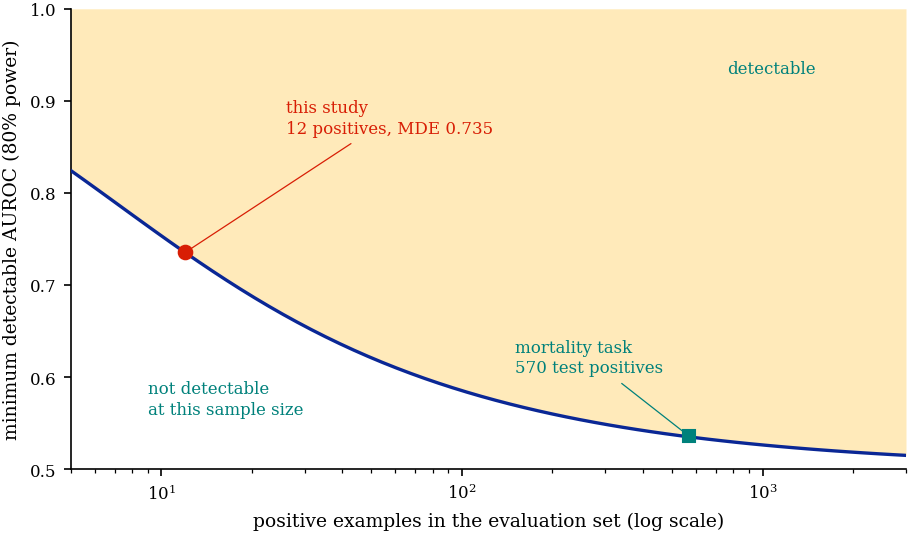

In [16]:
fig, ax = plt.subplots(figsize=(6.4, 3.7))
fig.subplots_adjust(left=0.115, right=0.985, top=0.975, bottom=0.145)
ax.plot(n_pos_grid, np.clip(mde_grid, 0.5, 1.0), color=DARK, lw=1.6, zorder=3)
ax.fill_between(n_pos_grid, np.clip(mde_grid, .5, 1), 1.0, color=FILL, alpha=.45, lw=0, zorder=1)
ax.text(760, 0.93, "detectable", fontsize=8.0, color=MID)
ax.text(9, 0.56, "not detectable\nat this sample size", fontsize=8.0, color=MID,
        linespacing=1.3)
# Both markers are placed on the curve the axes actually draw. The study marker
# used to be plotted at the stored 0.7382, which this curve does not pass through.
# Round marker for the study, square for the comparator: in a greyscale print the
# scarlet and the teal are close in luminance, so shape carries the distinction.
ax.plot([n_pos_study], [mde_study], "o", color=RED, ms=6.5, zorder=5)
ax.annotate(f"this study\n{n_pos_study} positives, MDE {mde_study:.3f}",
             (n_pos_study, mde_study), xytext=(26, 0.865),
             fontsize=8.0, color=RED, linespacing=1.3,
             arrowprops=dict(arrowstyle="-", lw=.6, color=RED))
ax.plot([mort_n_pos], [mort_mde], "s", color=MID, ms=5.5, zorder=5)
ax.annotate(f"mortality task\n{mort_n_pos} test positives", (mort_n_pos, mort_mde),
             xytext=(150, 0.605), fontsize=8.0, color=MID, linespacing=1.3,
             arrowprops=dict(arrowstyle="-", lw=.6, color=MID))
ax.set_xscale("log")
ax.set_xlabel("positive examples in the evaluation set (log scale)")
ax.set_ylabel(f"minimum detectable AUROC ({power_study * 100:.0f}% power)")
ax.set_ylim(0.5, 1.0)
ax.set_xlim(5, 3000)
if SHOW_INFIGURE_TITLES: ax.set_title("What each evaluation in this thesis could have seen", loc="left", fontsize=9.5, pad=8)

save_fig(fig, "fig-power.pdf")
plt.show()

## Figure 7: `fig-forest`

**Step 1. The data.** Read from `results/accord/stats/intervals.json`, `results/accord/decontam/corrected_gold_metrics.json`, `results/accord/control/final_report.json`, `results/task_runs.json`, `results/accord/scaling/scaling_results.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [17]:
p_intervals = os.path.join(RESULTS_ACCORD, "stats", "intervals.json")
d_intervals = json.load(open(p_intervals))
iv = d_intervals["E2_mcc_intervals"]

rows = []
for k, v in iv.items():
    rows.append((f"MCC, {k.replace('_', ' ')}", v["mcc"], v["ci95"][0], v["ci95"][1]))

p_decontam = os.path.join(RESULTS_ACCORD, "decontam", "corrected_gold_metrics.json")
d_decontam = json.load(open(p_decontam))
auroc_full = d_decontam["aggregate"]["ensemble_auroc"]
ci_full = d_decontam["aggregate"]["ensemble_ci95"]
rows.append(("AUROC minus 0.5 (decontaminated)", auroc_full - 0.5, ci_full[0] - 0.5, ci_full[1] - 0.5))

# Defect-free stratum, decontaminated. This row used to carry the E3 numbers from
# stats/intervals.json (0.5078, CI [0.2217, 0.7615]), which are computed on the
# contaminated released scores, so it was not comparable with the row above it.
p_control = os.path.join(RESULTS_ACCORD, "control", "final_report.json")
d_control = json.load(open(p_control))
df34 = d_control["ensemble_mean_of_seed_scores"]["gold_defect_free_rule34"]
rows.append(("AUROC minus 0.5 (defect-free stratum)", df34["auroc"] - 0.5,
             df34["bootstrap"]["ci95"][0] - 0.5, df34["bootstrap"]["ci95"][1] - 0.5))

p_task_runs = os.path.join(RESULTS, "task_runs.json")
d_task_runs = json.load(open(p_task_runs))
pb2 = [d_task_runs[f"concat_s{s}"]["auroc"] for s in (1, 2, 3)]
ou2 = [d_task_runs[f"ours_current_s{s}"]["auroc"] for s in (0, 1, 2)]
g = statistics.mean(pb2) - statistics.mean(ou2)
se = math.sqrt(statistics.stdev(pb2) ** 2 / 3 + statistics.stdev(ou2) ** 2 / 3)
rows.append(("C37 gap, PubMedBERT minus scratch", g, g - 1.96 * se, g + 1.96 * se))

p_scaling = os.path.join(RESULTS_ACCORD, "scaling", "scaling_results.json")
d_scaling = json.load(open(p_scaling))
p100 = [x["accuracy"] for x in d_scaling if x["tag"] == "scratch_100M"]
pbert = [x["accuracy"] for x in d_scaling if x["tag"] == "pretrained_bert"]
g44 = statistics.mean(pbert) - statistics.mean(p100)
se44 = math.sqrt(statistics.stdev(pbert) ** 2 / 3 + statistics.stdev(p100) ** 2 / 3)
rows.append(("C44 gap at 100M (AG News)", g44, g44 - 1.96 * se44, g44 + 1.96 * se44))

rows.sort(key=lambda r: r[1])

print("fig-forest: values plotted (sorted by estimate)")
for lab, est, lo, hi in rows:
    crosses = lo <= 0 <= hi
    print(f"  {lab:38s} est={est:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  {'crosses zero' if crosses else 'excludes zero'}")

fig-forest: values plotted (sorted by estimate)
  MCC, llama baseline                    est=-0.0436  95% CI [-0.2337, +0.0563]  crosses zero
  MCC, accord binary at 0.5 253core      est=-0.0070  95% CI [-0.1626, +0.0753]  crosses zero
  C37 gap, PubMedBERT minus scratch      est=+0.0031  95% CI [-0.0111, +0.0173]  crosses zero
  MCC, gpt4o fewshot                     est=+0.0117  95% CI [-0.1120, +0.1319]  crosses zero
  AUROC minus 0.5 (decontaminated)       est=+0.0145  95% CI [-0.1790, +0.2034]  crosses zero
  AUROC minus 0.5 (defect-free stratum)  est=+0.0469  95% CI [-0.2582, +0.3281]  crosses zero
  C44 gap at 100M (AG News)              est=+0.0518  95% CI [+0.0496, +0.0540]  excludes zero
  MCC, gpt4o zeroshot                    est=+0.1089  95% CI [-0.0319, +0.2484]  crosses zero


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-forest.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-forest.pdf


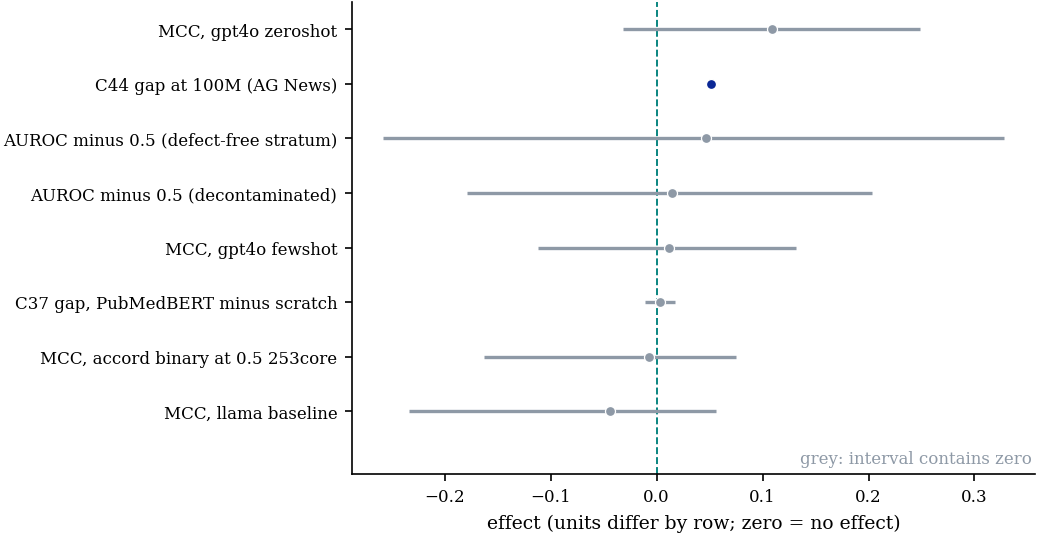

In [18]:
fig, ax = plt.subplots(figsize=(6.8, 3.7))
fig.subplots_adjust(left=0.315, right=0.985, top=0.985, bottom=0.135)
for i, (lab, e, lo, hi) in enumerate(rows):
    crosses = lo <= 0 <= hi
    c = DEAD if crosses else DARK
    ax.hlines(i, lo, hi, color=c, lw=1.6)
    ax.plot(e, i, "o", color=c, ms=4.8, markeredgecolor="w", markeredgewidth=0.6)
ax.axvline(0, color=MID, lw=0.9, ls="--", zorder=0)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([r[0] for r in rows], fontsize=8.0)
ax.set_xlabel("effect (units differ by row; zero = no effect)")
# One extra row of headroom at the bottom holds the key, so it no longer sits on
# the lowest interval.
ax.set_ylim(-1.15, len(rows) - 0.5)
n_cross = sum(1 for r in rows if r[2] <= 0 <= r[3])
if SHOW_INFIGURE_TITLES: ax.set_title(f"{n_cross} of {len(rows)} headline estimates cross zero", loc="left", fontsize=9.5, pad=8)
ax.text(0.995, 0.015, "grey: interval contains zero", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8.0, color=DEAD)

save_fig(fig, "fig-forest.pdf")
plt.show()

## Figure 8: `fig-disc-strata`

**Step 1. The data.** Read from `results/accord/decontam/corrected_gold_metrics.json`, `results/accord/control/final_report.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [19]:
p_decontam = os.path.join(RESULTS_ACCORD, "decontam", "corrected_gold_metrics.json")
d_decontam = json.load(open(p_decontam))

# Both rows now come from the decontaminated run. The defect-free stratum used to
# be read from stats/intervals.json E3, which is computed on the contaminated
# released scores, so the two rows were not comparable. Its stratified CI and its
# dropped-resample count belong to that superseded bootstrap and are no longer
# drawn; there is no decontaminated Mann-Whitney p for this stratum on disk, so
# that row carries none.
p_control = os.path.join(RESULTS_ACCORD, "control", "final_report.json")
d_control = json.load(open(p_control))
e3 = d_control["ensemble_mean_of_seed_scores"]["gold_defect_free_rule34"]

agg = d_decontam["aggregate"]
rows = [
    ("All non-ambiguous pairs\n(decontaminated 3-seed ensemble)",
     agg["ensemble_auroc"], agg["ensemble_ci95"], d_decontam["n"], d_decontam["n_positives"],
     agg["ensemble_mannwhitney_p"]),
    ("Rules 3+4 only\n(exemplar-defect-free by construction)",
     e3["auroc"], e3["bootstrap"]["ci95"], e3["n"], e3["pos"], None),
]

print("fig-disc-strata: values plotted")
for label, auroc, ci, n, pos, p in rows:
    p_txt = f"  MWU p={p:.3f}" if p is not None else "  (no matching decontaminated MWU p on disk)"
    print(f"  {label.replace(chr(10), ' '):55s} AUROC={auroc:.4f}  CI=[{ci[0]:.3f},{ci[1]:.3f}]  n={n}  pos={pos}{p_txt}")
print(f"  bootstrap: {d_control['bootstrap_n_resamples']} resamples, "
      f"{e3['bootstrap']['n_boot_valid']} valid on the defect-free stratum")
print("  first row is labelled 'non-ambiguous', not 'annotated': the annotated set is 299,")
print("  and the 46 ambiguous pairs are excluded from the 253 plotted.")

fig-disc-strata: values plotted
  All non-ambiguous pairs (decontaminated 3-seed ensemble) AUROC=0.5145  CI=[0.321,0.703]  n=253  pos=12  MWU p=0.867
  Rules 3+4 only (exemplar-defect-free by construction)   AUROC=0.5469  CI=[0.242,0.828]  n=134  pos=6  (no matching decontaminated MWU p on disk)
  bootstrap: 10000 resamples, 10000 valid on the defect-free stratum
  first row is labelled 'non-ambiguous', not 'annotated': the annotated set is 299,
  and the 46 ambiguous pairs are excluded from the 253 plotted.


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-disc-strata.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-disc-strata.pdf


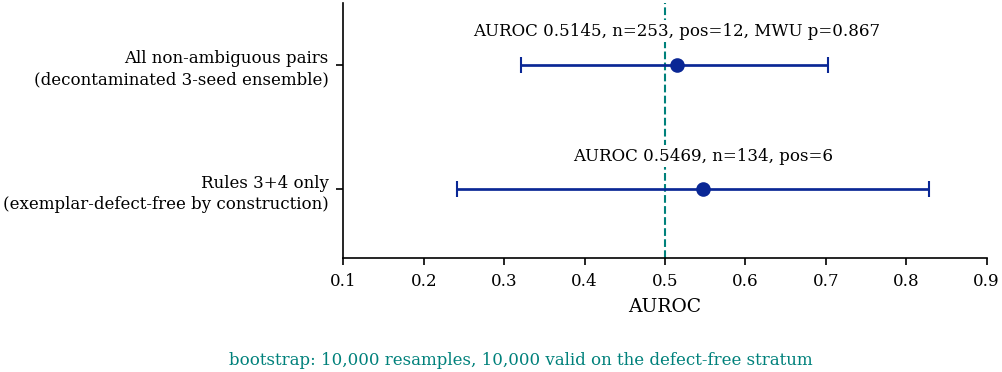

In [20]:
fig, ax = plt.subplots(figsize=(6.4, 2.7))
fig.subplots_adjust(left=0.315, right=0.985, top=0.93, bottom=0.30)
ys = np.arange(len(rows))[::-1]
ax.axvline(0.5, **CHANCE_STYLE)
for y, (label, auroc, ci, n, pos, p) in zip(ys, rows):
    ax.errorbar([auroc], [y], xerr=[[auroc - ci[0]], [ci[1] - auroc]], fmt="o",
                 color=DARK, capsize=4, markersize=6, linewidth=1.3, zorder=3)
    txt = f"AUROC {auroc:.4f}, n={n}, pos={pos}"
    if p is not None:
        txt += f", MWU p={p:.3f}"
    # White backing so the chance rule at 0.5 does not run through the digits.
    ax.text(auroc, y + 0.20, txt, ha="center", va="bottom", fontsize=8.0, zorder=4,
            bbox=dict(boxstyle="square,pad=0.15", facecolor="white", edgecolor="none"))
ax.set_yticks(ys)
ax.set_yticklabels([r[0] for r in rows], fontsize=8.0, linespacing=1.3)
ax.set_xlim(0.1, 0.9)
ax.set_ylim(-0.55, 1.5)
ax.set_xlabel("AUROC")
ax.spines[["top", "right"]].set_visible(False)
# Note sits below the axes, clear of both intervals.
fig.text(0.5, 0.035,
         f"bootstrap: {d_control['bootstrap_n_resamples']:,} resamples, "
         f"{e3['bootstrap']['n_boot_valid']:,} valid on the defect-free stratum",
         ha="center", fontsize=8.0, color=MID)
if SHOW_INFIGURE_TITLES: fig.suptitle("On evidence correct by construction, ranking is at chance,\nnot merely attenuated toward it",
              fontsize=8.3, y=0.99)
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.03,
          "No ROC curve is drawn: per-pair prediction scores are not committed to this repository (MIMIC-III DUA\n"
          "restricts released files to aggregates). Panels show the committed point estimate and its bootstrap CI instead.",
          ha="center", fontsize=8.0, color=MID)

save_fig(fig, "fig-disc-strata.pdf")
plt.show()

## Figure 9: `fig-scaling`

**Step 1. The data.** Read from `results/accord/scaling/scaling_results.json`, `results/task_runs.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [21]:
p_scaling = os.path.join(RESULTS_ACCORD, "scaling", "scaling_results.json")
d_scaling = json.load(open(p_scaling))
by, params_by_tag = {}, {}
for x in d_scaling:
    by.setdefault(x["tag"], []).append(x["accuracy"])
    params_by_tag[x["tag"]] = x["non_emb_params"]
tags = ["scratch_10M", "scratch_30M", "scratch_100M"]
xs = [params_by_tag[t] for t in tags]
mu = [statistics.mean(by[t]) for t in tags]
sd = [statistics.stdev(by[t]) for t in tags]
pm, ps, pp = statistics.mean(by["pretrained_bert"]), statistics.stdev(by["pretrained_bert"]), params_by_tag["pretrained_bert"]

p_task_runs = os.path.join(RESULTS, "task_runs.json")
d_task_runs = json.load(open(p_task_runs))
pb = [d_task_runs[f"concat_s{s}"]["auroc"] for s in (1, 2, 3)]
ou = [d_task_runs[f"ours_current_s{s}"]["auroc"] for s in (0, 1, 2)]
pbm, pbs = statistics.mean(pb), statistics.stdev(pb)
oum, ous = statistics.mean(ou), statistics.stdev(ou)
gap = pbm - oum
clinical_params = d_task_runs["ours_current_s0"]["non_emb_params"]

print("fig-scaling: values plotted")
print(f"  AG News: pretrained_bert mean +/- std = {pm:.4f} +/- {ps:.4f}  ({pp / 1e6:.0f}M params)")
for t, x, m, s in zip(tags, xs, mu, sd):
    print(f"  AG News: {t:14s} mean +/- std = {m:.4f} +/- {s:.4f}  ({x / 1e6:.1f}M params)  gap to pretrained = {pm - m:+.4f}")
print(f"  clinical task: PubMedBERT (concat_s1..3) AUROC mean +/- std = {pbm:.4f} +/- {pbs:.4f}")
print(f"  clinical task: from-scratch (ours_current_s0..2) AUROC mean +/- std = {oum:.4f} +/- {ous:.4f}  ({clinical_params / 1e6:.1f}M params)")
print(f"  clinical task gap: {gap:+.4f}")

fig-scaling: values plotted
  AG News: pretrained_bert mean +/- std = 0.9396 +/- 0.0010  (86M params)
  AG News: scratch_10M    mean +/- std = 0.8790 +/- 0.0040  (10.6M params)  gap to pretrained = +0.0606
  AG News: scratch_30M    mean +/- std = 0.8833 +/- 0.0009  (31.9M params)  gap to pretrained = +0.0563
  AG News: scratch_100M   mean +/- std = 0.8878 +/- 0.0016  (99.2M params)  gap to pretrained = +0.0518
  clinical task: PubMedBERT (concat_s1..3) AUROC mean +/- std = 0.7693 +/- 0.0102
  clinical task: from-scratch (ours_current_s0..2) AUROC mean +/- std = 0.7662 +/- 0.0073  (10.6M params)
  clinical task gap: +0.0031


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-scaling.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-scaling.pdf


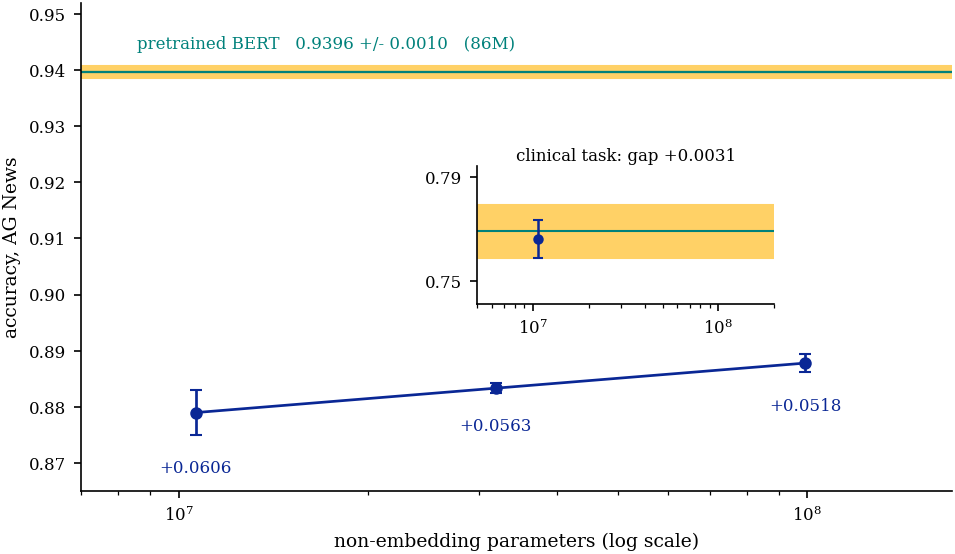

In [22]:
fig, ax = plt.subplots(figsize=(6.6, 3.9))
fig.subplots_adjust(left=0.105, right=0.985, top=0.97, bottom=0.135)
ax.axhspan(pm - ps, pm + ps, color=FILL, zorder=1)
ax.axhline(pm, color=MID, lw=1.1, zorder=2)
ax.text(8.6e6, pm + 0.0035, f"pretrained BERT   {pm:.4f} +/- {ps:.4f}   ({pp / 1e6:.0f}M)",
         fontsize=8.0, color=MID, va="bottom")
ax.errorbar(xs, mu, yerr=sd, fmt="-o", color=DARK, ms=5, lw=1.3, capsize=3, zorder=4)
# The gap labels sit below their points; the x limits are set wide enough that the
# leftmost one is not cut off by the axis, as it was before.
for x, m, s in zip(xs, mu, sd):
    ax.annotate(f"{pm - m:+.4f}", (x, m - s), textcoords="offset points", xytext=(0, -12),
                 ha="center", va="top", fontsize=8.0, color=DARK)
ax.set_xscale("log")
ax.set_xlabel("non-embedding parameters (log scale)")
ax.set_ylabel("accuracy, AG News")
ax.set_ylim(0.865, 0.952)
ax.set_xlim(7.0e6, 1.7e8)
if SHOW_INFIGURE_TITLES: ax.set_title("Pretraining is worth five points here, and more parameters do not close it",
              loc="left", fontsize=9.5, pad=8)

# The inset used to sit at the lower right, on top of the 100M point and its gap
# label. It now occupies the empty band between the scratch curve and the
# pretrained reference.
ins = fig.add_axes([0.505, 0.455, 0.30, 0.235])
ins.axhspan(pbm - pbs, pbm + pbs, color=FILL)
ins.axhline(pbm, color=MID, lw=1.0)
ins.errorbar([1.06e7], [oum], yerr=[ous], fmt="o", color=DARK, ms=4, capsize=2.5)
ins.set_xscale("log")
ins.set_xlim(5e6, 2e8)
ins.set_ylim(oum - 0.025, pbm + 0.025)
ins.set_title(f"clinical task: gap {gap:+.4f}", fontsize=8.0, pad=3)
ins.tick_params(labelsize=8)
ins.set_yticks([0.75, 0.79])
ins.set_xticks([1e7, 1e8])

save_fig(fig, "fig-scaling.pdf")
plt.show()

## Figure 10: `fig-threshold-surface`

**Step 1. The data.** Read from `results/accord/selection/threshold_robustness_results.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [23]:
p_thresh = os.path.join(RESULTS_ACCORD, "selection", "threshold_robustness_results.json")
d_thresh = json.load(open(p_thresh))
df = pd.DataFrame(d_thresh["cells"])
piv = df.pivot_table(index="achieved_rate", columns="beta", values="demographic_parity_gap", aggfunc="mean")
mde = df.pivot_table(index="achieved_rate", columns="beta", values="mde_demographic_parity_gap", aggfunc="mean")
R, B, Z, M = piv.index.values, piv.columns.values, piv.values, mde.values
e9_rate = d_thresh["original_e9_population_pred_pos_rate"]

# Named setting, not read from this file: the audit's own demographic-parity tolerance.
TOLERANCE = 0.05

print("fig-threshold-surface: values plotted")
print(f"  grid: {Z.shape[0]} operating points x {Z.shape[1]} selection strengths = {Z.size} cells")
print(f"  demographic-parity gap range: [{np.nanmin(Z):.4f}, {np.nanmax(Z):.4f}]")
print(f"  minimum-detectable-gap range: [{np.nanmin(M):.4f}, {np.nanmax(M):.4f}]")
n_under = int((M > TOLERANCE).sum())
print(f"  cells underpowered at TOLERANCE={TOLERANCE}: {n_under} of {M.size}")
print(f"  original E9 operating point (predicted-positive rate): {e9_rate:.4f}")

# White to amber to teal to blue: monotonically darkening (greyscale luminance
# 255, 211, 90, 43), so the surface still reads as a magnitude in a black and
# white print, and the hue path stays inside the range dichromats separate.
cmap = LinearSegmentedColormap.from_list(
    "acc", [(0.0, "#FFFFFF"), (0.34, FILL), (0.70, MID), (1.0, DARK)])

fig-threshold-surface: values plotted
  grid: 18 operating points x 15 selection strengths = 270 cells
  demographic-parity gap range: [0.0021, 0.2001]
  minimum-detectable-gap range: [0.0305, 0.0600]
  cells underpowered at TOLERANCE=0.05: 195 of 270
  original E9 operating point (predicted-positive rate): 0.1994


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-threshold-surface.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-threshold-surface.pdf


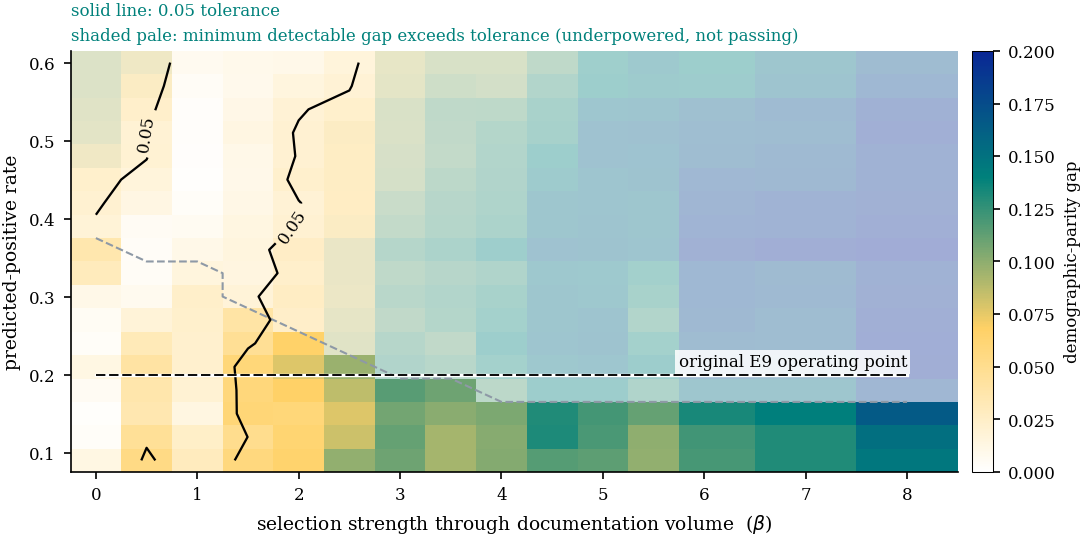

In [24]:
fig, ax = plt.subplots(figsize=(6.9, 3.9))
fig.subplots_adjust(left=0.085, right=0.995, top=0.855, bottom=0.135)
im = ax.pcolormesh(B, R, Z, cmap=cmap, shading="nearest", vmin=0, vmax=0.20)

# Veil the underpowered region instead of hatching it.
veil = np.where(M > TOLERANCE, 0.62, 0.0)
ax.pcolormesh(B, R, veil, cmap=LinearSegmentedColormap.from_list("v", ["#ffffff00", "#ffffff"]),
               shading="nearest", vmin=0, vmax=1, zorder=2)
ax.contour(B, R, (M > TOLERANCE).astype(float), levels=[0.5],
            colors=DEAD, linewidths=1.0, linestyles="dashed", zorder=3)

cs = ax.contour(B, R, Z, levels=[TOLERANCE], colors="k", linewidths=1.1, zorder=4)
ax.clabel(cs, fmt={TOLERANCE: f"{TOLERANCE}"}, fontsize=8.0, inline=True, inline_spacing=6)

ax.plot(B, [e9_rate] * len(B), color="w", lw=1.6, zorder=5)
ax.plot(B, [e9_rate] * len(B), color="k", lw=0.9, ls=(0, (5, 2)), zorder=6)
# Label parked at the right-hand end of the line it names. Anchored at the left
# of the panel it lay across the 0.05 contour.
ax.text(B[-1], e9_rate + 0.006, "original E9 operating point", ha="right", va="bottom",
        fontsize=8.0, color="k", zorder=7,
        bbox=dict(boxstyle="square,pad=0.2", facecolor="white", alpha=0.85, edgecolor="none"))

ax.set_xlabel(r"selection strength through documentation volume  ($\beta$)")
ax.set_ylabel("predicted-positive rate")
if SHOW_INFIGURE_TITLES: ax.set_title("The audit never becomes cleanly blind; it becomes unmeasurable", loc="left", fontsize=9.5, pad=16)
# Two lines above the axes: on one line this key ran the full width of the
# figure, over the colourbar and off the right-hand edge.
ax.text(0, 1.075, f"solid line: {TOLERANCE} tolerance", transform=ax.transAxes,
        fontsize=8.0, color=MID, va="bottom")
ax.text(0, 1.015, "shaded pale: minimum detectable gap exceeds tolerance "
        "(underpowered, not passing)", transform=ax.transAxes,
        fontsize=8.0, color=MID, va="bottom")

cb = fig.colorbar(im, ax=ax, pad=0.015, fraction=0.043)
cb.set_label("demographic-parity gap", fontsize=8.0)
cb.ax.tick_params(labelsize=8)
cb.outline.set_linewidth(0.5)

save_fig(fig, "fig-threshold-surface.pdf")
plt.show()

## Figure 11: `fig-disc-actionability`

**Step 1. The data.** This figure is a schematic: it reads no result file, and the cell below says so rather than implying a source it does not have.

In [25]:
print("fig-disc-actionability: no result file is read by this cell.")
print("This figure is a schematic of a MIMIC-III field-availability fact (accord/CORRECTIONS.md, C6):")
print("  nursing notes carry CHARTTIME (a timestamp); discharge summaries carry only CHARTDATE (a date).")
print("No numeric estimate is plotted, so there is no CI to attach and nothing to source from a JSON file.")

# Widened from 10.5 to 11.6 units so the longest event label no longer runs off
# the right-hand edge, and every leader now starts outside the shaded band
# instead of crossing it. The trigger point carries one marker, not an X drawn
# on top of a dot.

fig-disc-actionability: no result file is read by this cell.
This figure is a schematic of a MIMIC-III field-availability fact (accord/CORRECTIONS.md, C6):
  nursing notes carry CHARTTIME (a timestamp); discharge summaries carry only CHARTDATE (a date).
No numeric estimate is plotted, so there is no CI to attach and nothing to source from a JSON file.


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-disc-actionability.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-disc-actionability.pdf


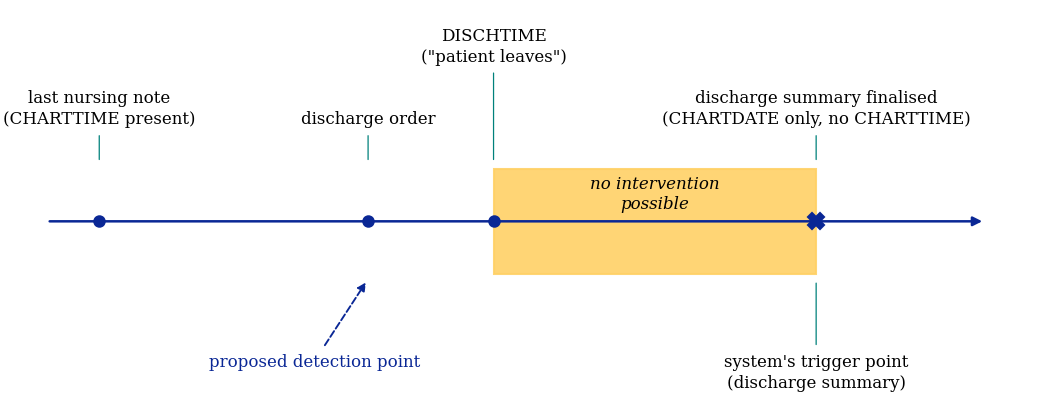

In [26]:
fig, ax = plt.subplots(figsize=(7.0, 2.7))
fig.subplots_adjust(left=0.005, right=0.995, top=0.995, bottom=0.005)
y_lo, y_hi = 0.85, 4.05
ax.set_xlim(0, 11.6)
ax.set_ylim(y_lo, y_hi)
ax.axis("off")

line_y = 2.3
band_lo, band_hi = line_y - 0.42, line_y + 0.42
events = [
    (1.0, "last nursing note\n(CHARTTIME present)", 3.05, "o"),
    (4.0, "discharge order", 3.05, "o"),
    (5.4, "DISCHTIME\n(\"patient leaves\")", 3.55, "o"),
    (9.0, "discharge summary finalised\n(CHARTDATE only, no CHARTTIME)", 3.05, "X"),
]
ax.annotate("", xy=(10.9, line_y), xytext=(0.4, line_y),
             arrowprops=dict(arrowstyle="-|>", color=DARK, lw=1.2))
for x, label, ytext, marker in events:
    ax.plot([x], [line_y], marker=marker, color=DARK,
            markersize=5 if marker == "o" else 8, zorder=4)
    ax.annotate(label, (x, band_hi + 0.04), xytext=(x, ytext), ha="center", va="bottom",
                 fontsize=8.0, linespacing=1.3,
                 arrowprops=dict(arrowstyle="-", color=MID, lw=0.6))

ax.axvspan(5.4, 9.0, ymin=(band_lo - y_lo) / (y_hi - y_lo),
           ymax=(band_hi - y_lo) / (y_hi - y_lo), color=FILL, alpha=0.9, zorder=1)
# Sits above the timeline rather than straddling it, so the arrow does not run
# between the two lines of the label.
ax.text((5.4 + 9.0) / 2, line_y + 0.07, "no intervention\npossible", ha="center",
         va="bottom", fontsize=8.0, style="italic", zorder=5, linespacing=1.25)

ax.annotate("system's trigger point\n(discharge summary)", xy=(9.0, band_lo - 0.04),
             xytext=(9.0, 1.25), ha="center", va="top", fontsize=8.0, linespacing=1.3,
             arrowprops=dict(arrowstyle="-", color=MID, lw=0.6))

ax.annotate("proposed detection point", xy=(4.0, band_lo - 0.04), xytext=(3.4, 1.25),
             fontsize=8.0, ha="center", va="top", color=DARK,
             arrowprops=dict(arrowstyle="-|>", color=DARK, lw=0.9, linestyle="--"))

if SHOW_INFIGURE_TITLES: ax.set_title("The actionability flaw: the trigger fires after the patient has left", fontsize=8.5, pad=8)
if SHOW_INFIGURE_NOTES: fig.text(0.5, 0.02,
          "Schematic of MIMIC-III field timing (CORRECTIONS.md C6: CHARTTIME is null for every\n"
          "discharge summary). No numeric estimate is shown; not sourced from a results JSON.",
          ha="center", fontsize=8.0, color=MID)

save_fig(fig, "fig-disc-actionability.pdf")
plt.show()

## Figure 12: `fig-met-exchange`

**Step 1. The data.** Read from `results/accord/diag/step3_baselines.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [27]:
p_baselines = os.path.join(RESULTS_ACCORD, "diag", "step3_baselines.json")
d_baselines = json.load(open(p_baselines))
systems = {
    "ACCORD": d_baselines["accord_binary_at_0.5_253core"],
    "GPT-4o zero-shot": d_baselines["gpt4o_zeroshot"],
    "GPT-4o few-shot": d_baselines["gpt4o_fewshot"],
    "Llama 3 8B": d_baselines["llama_baseline"],
}
ref = systems["ACCORD"]
TP0, TN0, FP0, FN0 = ref["tp"], ref["tn"], ref["fp"], ref["fn"]
P = TP0 + FN0
N = TN0 + FP0

def mcc_from_counts(tp, tn, fp, fn):
    num = tp * tn - fp * fn
    den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return 0.0 if den == 0 else num / den

mcc0 = mcc_from_counts(TP0, TN0, FP0, FN0)

print("fig-met-exchange: values plotted")
print(f"  reference system (ACCORD): TP={TP0}, TN={TN0}, FP={FP0}, FN={FN0}  (P={P}, N={N}, n={P + N})")
print(f"  reference MCC: {mcc0:.4f}")
for name, s in systems.items():
    delta = TP0 - s["tp"]
    dtn = s["tn"] - TN0
    print(f"  {name:18s}: TP={s['tp']:3d} TN={s['tn']:3d} FP={s['fp']:3d} FN={s['fn']:3d}  delta_TP={delta:+d}  delta_TN={dtn:+d}")

fig-met-exchange: values plotted
  reference system (ACCORD): TP=11, TN=18, FP=223, FN=1  (P=12, N=241, n=253)
  reference MCC: -0.0070
  ACCORD            : TP= 11 TN= 18 FP=223 FN=  1  delta_TP=+0  delta_TN=+0
  GPT-4o zero-shot  : TP=  6 TN=176 FP= 65 FN=  6  delta_TP=+5  delta_TN=+158
  GPT-4o few-shot   : TP=  7 TN=107 FP=134 FN=  5  delta_TP=+4  delta_TN=+89
  Llama 3 8B        : TP= 11 TN= 10 FP=231 FN=  1  delta_TP=+0  delta_TN=-8


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-met-exchange.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-met-exchange.pdf


/var/folders/l6/86mnt0714mqc2ff55k1qp1pw0000gn/T/ipykernel_67024/1758245001.py:16: RuntimeWarning: invalid value encountered in sqrt
  den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))


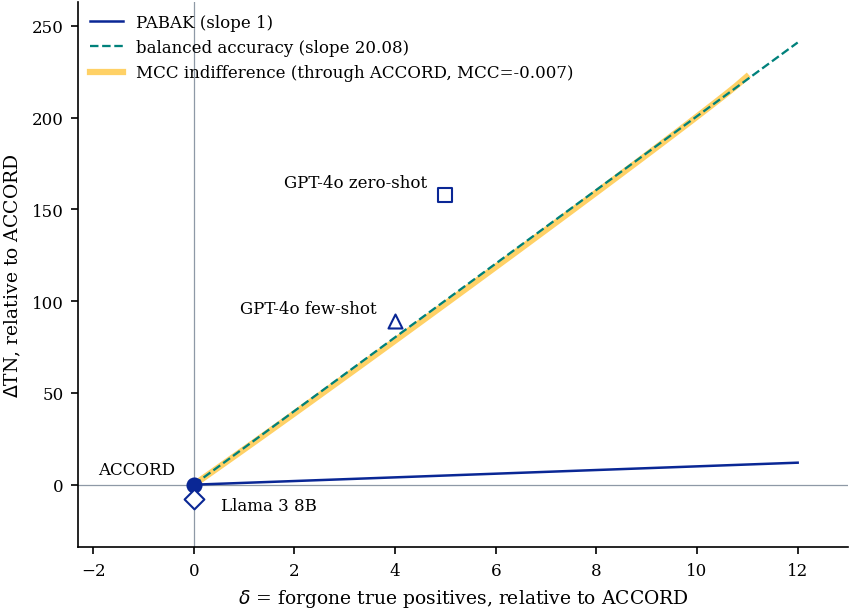

In [28]:
fig, ax = plt.subplots(figsize=(5.9, 4.2))
fig.subplots_adjust(left=0.115, right=0.985, top=0.98, bottom=0.115)
d = np.linspace(0, P, 200)
ax.plot(d, d, color=DARK, linewidth=1.2, zorder=3, label="PABAK (slope 1)")
slope_ba = N / P
ax.plot(d, d * slope_ba, color=MID, linewidth=1.1, linestyle="--", zorder=3,
        label=f"balanced accuracy (slope {slope_ba:.2f})")

# MCC indifference curve through ACCORD's own operating point, traced numerically: for
# each delta (forgone TPs), solve for the TN that holds MCC constant at mcc0.
deltas = np.linspace(0, P, 60)
dtn_curve = []
for delta in deltas:
    tp = TP0 - delta
    fn = P - tp

    def f(tn):
        fp = N - tn
        return mcc_from_counts(tp, tn, fp, fn) - mcc0

    try:
        tn_sol = brentq(f, 0, N)
        dtn_curve.append(tn_sol - TN0)
    except ValueError:
        dtn_curve.append(np.nan)
# Thick amber underneath, thin teal dashes on top: the two curves very nearly
# coincide, and this way both stay visible without either hiding the other.
ax.plot(deltas, dtn_curve, color=FILL, linewidth=3.0, zorder=2,
        label=f"MCC indifference (through ACCORD, MCC={mcc0:.3f})")

markers = {"ACCORD": "o", "GPT-4o zero-shot": "s", "GPT-4o few-shot": "^", "Llama 3 8B": "D"}
# Every label is placed away from the two near-coincident diagonals: the GPT
# points are labelled up and to the left of the lines, ACCORD to the left of the
# origin, Llama below the flat PABAK line.
label_offset = {"ACCORD": (-9, 7), "GPT-4o zero-shot": (-9, 6), "GPT-4o few-shot": (-9, 6),
                "Llama 3 8B": (13, -3)}
label_align = {"ACCORD": "right", "GPT-4o zero-shot": "right", "GPT-4o few-shot": "right",
               "Llama 3 8B": "left"}
for name, s in systems.items():
    delta = TP0 - s["tp"]
    dtn = s["tn"] - TN0
    ax.scatter([delta], [dtn], marker=markers[name], s=45, color=DARK,
                facecolor="white" if name != "ACCORD" else DARK, zorder=5)
    ax.annotate(name, (delta, dtn), textcoords="offset points", xytext=label_offset[name],
                ha=label_align[name], va="center", fontsize=8.0, zorder=6)

ax.axhline(0, color=DEAD, linewidth=0.6, zorder=0)
ax.axvline(0, color=DEAD, linewidth=0.6, zorder=0)
ax.set_xlabel(r"$\delta$ = forgone true positives, relative to ACCORD")
ax.set_ylabel(r"$\Delta$TN, relative to ACCORD")
ax.set_xlim(-2.3, P + 1)
ax.set_ylim(-34, N + 22)
ax.legend(loc="upper left", fontsize=8.0, frameon=False, borderaxespad=0.3)
ax.spines[["top", "right"]].set_visible(False)
if SHOW_INFIGURE_TITLES: ax.set_title(f"What each statistic trades (P={P}, N={N}, n={P + N})", fontsize=8.5)

save_fig(fig, "fig-met-exchange.pdf")
plt.show()

## Figure 13: `fig-exemplar`

**Step 1. The data.** Read from `results/accord/exemplar/exemplar_correctness_recomputed.json`. Every value plotted below is printed first, so you can check the figure against the file it came from.

In [29]:
p_exemplar = os.path.join(RESULTS_ACCORD, "exemplar", "exemplar_correctness_recomputed.json")
d_exemplar = json.load(open(p_exemplar))
ex = d_exemplar["rule_1_2_pooled"]
defect_rate = ex["n_wrong"] / ex["n_resolved"]

print("fig-exemplar: values plotted")
print(f"  rule_1_2_pooled: n_wrong={ex['n_wrong']}, n_resolved={ex['n_resolved']}, defect_rate={defect_rate:.4f}")

# Widened and re-anchored. Previously the trigger caption ran into the
# "Discharge summary" heading, both leader arrows crossed a slot box and struck
# through its label, the right-hand annotations ran off the axes, and the summary
# text was wider than the box drawn around it.

fig-exemplar: values plotted
  rule_1_2_pooled: n_wrong=65, n_resolved=137, defect_rate=0.4745


**Step 2. The figure.** Drawn only from the values printed above, then written to `fig-exemplar.pdf`.

saved: /Users/rickygole/provenance-encoder/accord/thesis/figures/fig-exemplar.pdf


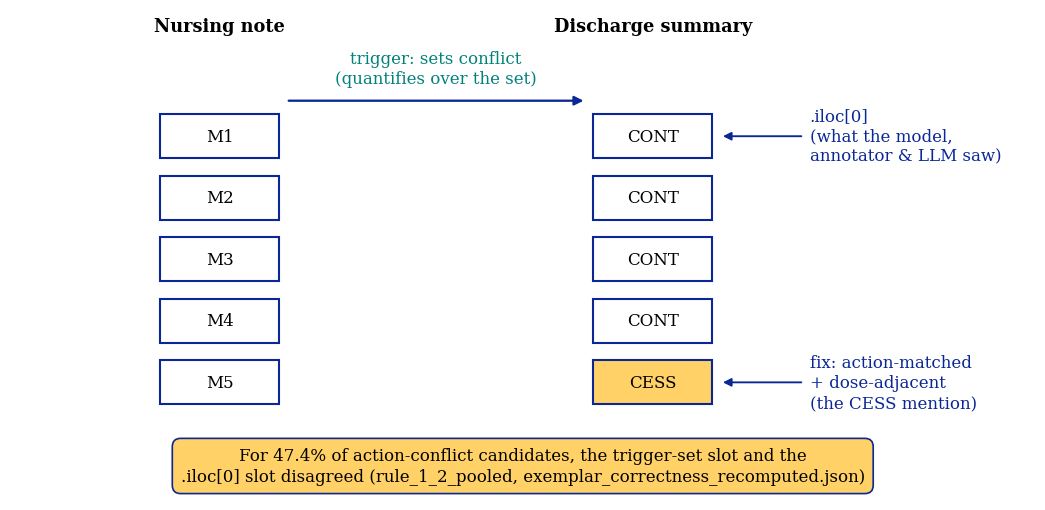

In [30]:
fig, ax = plt.subplots(figsize=(7.0, 3.4))
fig.subplots_adjust(left=0.005, right=0.995, top=0.995, bottom=0.005)
ax.set_xlim(0, 9.6)
ax.set_ylim(0, 6.4)
ax.axis("off")

col_x = {"Nursing note": 2.0, "Discharge summary": 6.0}
half_w = 0.55
for label, x in col_x.items():
    ax.text(x, 6.1, label, ha="center", va="center", fontsize=8.5, weight="bold")

nurse_tags = ["M1", "M2", "M3", "M4", "M5"]
disch_tags = ["CONT", "CONT", "CONT", "CONT", "CESS"]
rows_y = [4.7 - i * 0.78 for i in range(5)]
for i, y in enumerate(rows_y):
    ax.add_patch(mpatches.Rectangle((col_x["Nursing note"] - half_w, y - 0.28), 2 * half_w, 0.56,
                                      facecolor="white", edgecolor=DARK))
    ax.text(col_x["Nursing note"], y, nurse_tags[i], ha="center", va="center", fontsize=8.0)
    fc = FILL if i == 4 else "white"
    ax.add_patch(mpatches.Rectangle((col_x["Discharge summary"] - half_w, y - 0.28), 2 * half_w, 0.56,
                                      facecolor=fc, edgecolor=DARK))
    ax.text(col_x["Discharge summary"], y, disch_tags[i], ha="center", va="center", fontsize=8.0)

# trigger arrow spanning both columns, above the slots and below the headings
ax.annotate("", xy=(col_x["Discharge summary"] - half_w - 0.05, 5.15),
             xytext=(col_x["Nursing note"] + half_w + 0.05, 5.15),
             arrowprops=dict(arrowstyle="-|>", color=DARK, lw=1.1))
ax.text((col_x["Nursing note"] + col_x["Discharge summary"]) / 2, 5.32,
         "trigger: sets conflict\n(quantifies over the set)", ha="center", va="bottom",
         fontsize=8.0, color=MID, linespacing=1.25)

# Leader arrows attach to the right edge of the slot they name, so they no longer
# cross the box and strike through the tag inside it.
x_note = col_x["Discharge summary"] + half_w + 0.9
ax.annotate(".iloc[0]\n(what the model,\nannotator & LLM saw)",
             xy=(col_x["Discharge summary"] + half_w + 0.06, rows_y[0]),
             xytext=(x_note, rows_y[0]), va="center", ha="left",
             fontsize=8.0, color=DARK, linespacing=1.25,
             arrowprops=dict(arrowstyle="-|>", color=DARK, lw=0.9))
ax.annotate("fix: action-matched\n+ dose-adjacent\n(the CESS mention)",
             xy=(col_x["Discharge summary"] + half_w + 0.06, rows_y[4]),
             xytext=(x_note, rows_y[4]), va="center", ha="left",
             fontsize=8.0, color=DARK, linespacing=1.25,
             arrowprops=dict(arrowstyle="-|>", color=DARK, lw=0.9))

summary = (f"For {defect_rate * 100:.1f}% of action-conflict candidates, the trigger-set slot and the\n"
           ".iloc[0] slot disagreed (rule_1_2_pooled, exemplar_correctness_recomputed.json)")
ax.text(4.8, 0.52, summary, ha="center", va="center", fontsize=8.0, linespacing=1.35,
        bbox=dict(boxstyle="round,pad=0.5", facecolor=FILL, edgecolor=DARK, linewidth=0.8))

save_fig(fig, "fig-exemplar.pdf")
plt.show()

## Final: verify all thirteen exist, then copy to Drive

Checks that every figure this notebook is supposed to produce is actually on disk (run any missing
figure cells above first), then, if running in Colab, copies the thirteen PDFs back to Drive.

In [31]:
EXPECTED = [
    "fig-pipeline-status.pdf",
    "fig-intro-headline.pdf",
    "fig-rule-precision.pdf",
    "fig-prevalence-response.pdf",
    "fig-falsification.pdf",
    "fig-power.pdf",
    "fig-forest.pdf",
    "fig-disc-strata.pdf",
    "fig-scaling.pdf",
    "fig-threshold-surface.pdf",
    "fig-disc-actionability.pdf",
    "fig-met-exchange.pdf",
    "fig-exemplar.pdf",
]

print(f"checking that all {len(EXPECTED)} thesis figures are present in {FIGDIR}")
missing = []
for name in EXPECTED:
    path = os.path.join(FIGDIR, name)
    ok = os.path.exists(path)
    print(f"  {'ok     ' if ok else 'MISSING'}  {name}")
    if not ok:
        missing.append(name)

if missing:
    print(f"\n{len(missing)} of {len(EXPECTED)} missing. Run the missing figure cells above, then re-run this cell.")
else:
    print(f"\nall {len(EXPECTED)} figures present.")

if not missing and IN_COLAB:
    OUT_DRIVE = "/content/drive/MyDrive/This is paper/02_figures"
    n = 0
    for name in EXPECTED:
        shutil.copy(os.path.join(FIGDIR, name), os.path.join(OUT_DRIVE, name))
        n += 1
    print(f"copied {n} figures to {OUT_DRIVE}")
elif not IN_COLAB:
    print("not running in Colab; skipping the copy-to-Drive step (figures are already in the local repository checkout).")

checking that all 13 thesis figures are present in /Users/rickygole/provenance-encoder/accord/thesis/figures
  ok       fig-pipeline-status.pdf
  ok       fig-intro-headline.pdf
  ok       fig-rule-precision.pdf
  ok       fig-prevalence-response.pdf
  ok       fig-falsification.pdf
  ok       fig-power.pdf
  ok       fig-forest.pdf
  ok       fig-disc-strata.pdf


  ok       fig-scaling.pdf
  ok       fig-threshold-surface.pdf
  ok       fig-disc-actionability.pdf
  ok       fig-met-exchange.pdf
  ok       fig-exemplar.pdf

all 13 figures present.
not running in Colab; skipping the copy-to-Drive step (figures are already in the local repository checkout).
